# Fraud Detection in Online Transactions
**End-to-end fraud detection: validation, EDA, features, modelling, threshold tuning and risk tiers**

Case: PaySphere Digital Payments, a fictional Indian digital-payments company (UPI, cards, net banking, wallets)

---
**What is in this notebook**

1. Business problem and objectives
2. Loading the data and checking it against the Data Definition
3. Data validation and cleaning
4. Exploratory analysis + statistical tests
5. Feature engineering
6. Train / validation / test split and data prep
7. Modelling (imbalance handling, model comparison, tuning)
8. Final model evaluation
9. Threshold tuning
10. Risk score and recommended actions
11. What drives the model + error analysis
12. Recommendations, limitations, next steps

## 1. Business problem and objectives

PaySphere handles a huge number of payments every month (UPI, cards, net banking, wallets). The fraud team is
worried about two things that pull in opposite directions:

* **Missed fraud (false negatives)**: the fraud goes through and turns into a chargeback, so PaySphere loses the money.
* **False alarms (false positives)**: a genuine customer gets blocked or annoyed, and the platform loses revenue and trust.

The Chief Risk Officer wants a model that can score every transaction in real time, plus a sensible cut-off, plus a
clear action for each risk level (allow, OTP challenge, manual review, block).

**My analytical objectives**

1. Check the data properly (keys, nulls, ranges, dates, business rules) and fix what can be fixed.
2. Find out which signals actually go together with fraud, and back that up with statistical tests, not just charts.
3. Build behaviour / risk features and check honestly whether they help.
4. Deal with the class imbalance and compare a few models using metrics that make sense for imbalanced data
   (PR-AUC mainly, not accuracy).
5. Tune the fraud cut-off using a cost view (a missed fraud is much more expensive than a false alarm).
6. Turn the model output into a 0-100 risk score with actions for each band.

**How I will judge success.** The company has not given fixed numeric targets, so I compare against simple baselines:
a random guess (PR-AUC equal to the fraud rate) and a simple rule (flag if device or location changed). I also look at
how much fraud is caught at a fixed review workload (top 20% riskiest transactions), and the rupee savings after
false alarm costs.

**Assumptions I am making**

* `amount` is in rupees.
* The label `is_fraud` is the final confirmed outcome (chargeback confirmed).
* The CSV file is the source of truth for column names. (The Data Definition does not match it perfectly, see section 2.)
* Cost numbers used for threshold tuning are my own assumptions, listed clearly in section 9 so they can be changed.

In [1]:
# Basic imports. Everything here is standard scikit-learn stack so it runs on any normal Anaconda setup.
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import TimeSeriesSplit, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

import joblib

SEED = 42
np.random.seed(SEED)

# same two colours for genuine / fraud in every chart so it is easy to follow
BLUE = "#2a78d6"     # genuine
ORANGE = "#eb6834"   # fraud
GREY = "#8a8a85"
PAL = {0: BLUE, 1: ORANGE}

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "axes.titleweight": "bold", "axes.titlesize": 11, "axes.grid.axis": "y",
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

## 2. Loading the data and comparing it with the Data Definition

There is one transaction table and one Data Definition file. Before touching the data I want to know if the two
actually match, because everything else depends on knowing what each column means.

In [2]:
df_raw = pd.read_csv("Datasets/transactions_fraud.csv")
defn = pd.read_excel("Data Definition.xlsx")

print("transactions:", df_raw.shape)
print("data definition rows:", defn.shape[0])
df_raw.head()

transactions: (50000, 25)
data definition rows: 25


,transaction_id,customer_id,device_id,merchant_id,timestamp,amount,payment_method,is_international,merchant_category,ip_address_risk_score,device_trust_score,txn_count_last_24h,avg_amount_last_24h,merchant_diversity_last_7d,device_change_flag,location_change_flag,authentication_method,otp_success_rate_customer,past_fraud_count_customer,past_disputes_customer,merchant_historical_fraud_rate,hour_of_day,day_of_week,is_weekend,is_fraud
0,1,1357,20937,720,1/18/24 19:23,18780.52,WALLET,0,Travel,0.243550,0.116606,7,6055.25,3,0,0,NONE,0.769328,1,2,0.069502,19,3,0,0
1,2,4095,29542,764,3/30/24 2:22,18955.06,CARD,0,Electronics,0.119761,0.030579,1,13366.74,5,0,1,OTP,0.468411,1,1,0.010010,2,5,1,0
2,3,3618,25236,671,1/4/24 17:26,10743.34,UPI,0,Fashion,0.565367,0.183770,0,7359.14,4,0,0,PIN,0.464356,0,1,0.118434,17,3,0,0
3,4,2755,29904,624,1/27/24 16:00,5054.75,CARD,0,Utilities,0.843842,0.717286,5,10923.57,6,0,0,PIN,0.635799,0,3,0.114947,16,5,1,0
4,5,2732,24151,501,2/20/24 23:14,14799.50,CARD,0,Gaming,0.202402,0.041616,11,6027.72,10,1,0,OTP,0.684301,2,0,0.014550,23,1,0,0


In [3]:
# Compare the column names in the CSV with the column names in the Data Definition
csv_cols = set(df_raw.columns)
def_cols = set(defn["Column Name"])

print("in both:", len(csv_cols & def_cols))
print("\nin Data Definition but NOT in the CSV:")
print(sorted(def_cols - csv_cols))
print("\nin the CSV but NOT in the Data Definition:")
print(sorted(csv_cols - def_cols))

in both: 15

in Data Definition but NOT in the CSV:
['customer_tenure_days', 'historical_fraud_rate', 'ip_address_country_match', 'location_risk_score', 'previous_chargeback_count', 'time_of_day', 'transaction_success_rate_customer', 'velocity_1h', 'velocity_24h', 'velocity_7d']

in the CSV but NOT in the Data Definition:
['authentication_method', 'avg_amount_last_24h', 'device_change_flag', 'hour_of_day', 'location_change_flag', 'merchant_diversity_last_7d', 'otp_success_rate_customer', 'past_disputes_customer', 'past_fraud_count_customer', 'txn_count_last_24h']


So only 15 of the 25 columns match by name. The other 10 on each side look like they describe similar ideas
with different names. My best guess at the closest pairs (this is my own reading, not something given in the files):

| Data Definition | CSV column | how close is it |
|---|---|---|
| `time_of_day` | `hour_of_day` | same thing |
| `velocity_24h` | `txn_count_last_24h` | same idea |
| `historical_fraud_rate` | `past_fraud_count_customer` | count instead of a rate |
| `previous_chargeback_count` | `past_disputes_customer` | disputes are close to chargebacks |
| `transaction_success_rate_customer` | `otp_success_rate_customer` | only OTP part |
| `location_risk_score` | `location_change_flag` | flag instead of a score |
| `velocity_1h`, `velocity_7d`, `customer_tenure_days`, `ip_address_country_match` | none | not available |

The CSV also has some columns that are not in the definition at all (`avg_amount_last_24h`, `merchant_diversity_last_7d`,
`device_change_flag`, `authentication_method`, `past_disputes_customer`). For those I use the column name to decide the
meaning. I will use the CSV as the source of truth, and I would raise this mismatch with the data owner.

Another thing I noticed: the problem statement says fraud is *less than 0.5%* of the transactions, but I will show
below that this file has around 10% fraud. So the imbalance here is milder than the problem description suggests (it says under 0.5%).

## 3. Data validation and cleaning

I run four kinds of checks: keys, nulls/incorrect values, business rules, and dates. I keep a small log
(`val_log`) so that at the end I have one table showing what I found and what I did about it.

In [4]:
val_log = []
def log_check(check, rows, action):
    val_log.append({"check": check, "rows_affected": int(rows), "action": action})

df = df_raw.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   transaction_id                  50000 non-null  int64  
 1   customer_id                     50000 non-null  int64  
 2   device_id                       50000 non-null  int64  
 3   merchant_id                     50000 non-null  int64  
 4   timestamp                       50000 non-null  object 
 5   amount                          50000 non-null  float64
 6   payment_method                  50000 non-null  object 
 7   is_international                50000 non-null  int64  
 8   merchant_category               50000 non-null  object 
 9   ip_address_risk_score           50000 non-null  float64
 10  device_trust_score              50000 non-null  float64
 11  txn_count_last_24h              50000 non-null  int64  
 12  avg_amount_last_24h             

### 3.1 Nulls and duplicates

In [5]:
print("total nulls:", df.isna().sum().sum())
print("fully duplicated rows:", df.duplicated().sum())
print("duplicated transaction_id:", df["transaction_id"].duplicated().sum())

# The authentication_method value "NONE" is a real category (no extra authentication used), not a missing value.
# pandas did not turn it into NaN, which I confirmed above (0 nulls), but worth remembering.
print(df["authentication_method"].value_counts())

log_check("Null values (all columns)", df.isna().sum().sum(), "none found, nothing to do")
log_check("Fully duplicated rows", df.duplicated().sum(), "none found")
log_check("transaction_id unique (primary key)", df["transaction_id"].duplicated().sum(), "unique, OK")

total nulls: 0
fully duplicated rows: 0
duplicated transaction_id: 0
authentication_method
OTP     29842
3DS      7687
PIN      7401
NONE     5070
Name: count, dtype: int64


### 3.2 Key consistency (primary / foreign key style checks)

There is only one table, so there are no real foreign keys to join. What I can check is whether `customer_id`,
`device_id` and `merchant_id` behave like proper entity keys. For example, one merchant should have one category,
and a "merchant fraud rate" should be one number per merchant.

In [6]:
print("unique customers:", df.customer_id.nunique(), "| id range:", df.customer_id.min(), "-", df.customer_id.max())
print("unique devices  :", df.device_id.nunique(), "| id range:", df.device_id.min(), "-", df.device_id.max())
print("unique merchants:", df.merchant_id.nunique(), "| id range:", df.merchant_id.min(), "-", df.merchant_id.max())
print("transactions per customer (min / median / max):",
      df.customer_id.value_counts().min(), "/", df.customer_id.value_counts().median(), "/", df.customer_id.value_counts().max())

# 1) does each merchant belong to one category?
cats_per_merchant = df.groupby("merchant_id")["merchant_category"].nunique()
print("\ncategories per merchant (should be 1):", cats_per_merchant.describe()[["min", "mean", "max"]].to_dict())

# 2) is merchant_historical_fraud_rate a constant per merchant?
rates_per_merchant = df.groupby("merchant_id")["merchant_historical_fraud_rate"].nunique()
print("distinct merchant_historical_fraud_rate values per merchant (should be 1):", rates_per_merchant.mean().round(1))

# 3) customer level columns should also be fairly stable for one customer
for c in ["past_fraud_count_customer", "past_disputes_customer", "otp_success_rate_customer"]:
    print(f"distinct {c} per customer:", df.groupby("customer_id")[c].nunique().mean().round(1))

# 4) how many devices does one customer use / how many customers share one device
print("\ndevices per customer (mean / max):", df.groupby("customer_id").device_id.nunique().mean().round(1),
      "/", df.groupby("customer_id").device_id.nunique().max())
print("customers per device (mean / max):", df.groupby("device_id").customer_id.nunique().mean().round(1),
      "/", df.groupby("device_id").customer_id.nunique().max())

unique customers: 4000 | id range: 1000 - 4999
unique devices  : 9946 | id range: 20000 - 29999
unique merchants: 300 | id range: 500 - 799
transactions per customer (min / median / max): 2 / 12.0 / 27

categories per merchant (should be 1): {'min': 6.0, 'mean': 6.0, 'max': 6.0}
distinct merchant_historical_fraud_rate values per merchant (should be 1): 166.7
distinct past_fraud_count_customer per customer: 3.0
distinct past_disputes_customer per customer: 4.6
distinct otp_success_rate_customer per customer: 12.5

devices per customer (mean / max): 12.5 / 27
customers per device (mean / max): 5.0 / 15


This is an important finding. The ID columns do **not** behave like real entity keys:

* every merchant shows up under all 6 categories,
* `merchant_historical_fraud_rate` changes from row to row for the same merchant,
* "customer level" columns like `past_fraud_count_customer` change from row to row for the same customer,
* a customer uses about 12 different devices in 3 months, and a device is shared by about 5 customers.

I can't fix this, because I have no other source to tell me the true merchant category or the true customer history.
So my decision: keep the columns, but treat them as **per-transaction attributes** (which is what they effectively are
in this file) and not as trustworthy entity profiles. I will also be careful about how much I trust ID-based features later.

In [7]:
log_check("merchant_id -> merchant_category one-to-one (count = merchants breaking it)", (cats_per_merchant > 1).sum(),
          "NOT true (every merchant has 6 categories). Can't fix, using merchant_category as a per-transaction field")
log_check("Merchant fraud rate constant per merchant (count = merchants breaking it)", (rates_per_merchant > 1).sum(),
          "NOT constant. Treated as per-transaction attributes, not entity profiles")

### 3.3 Range and value checks

In [8]:
score_cols = ["ip_address_risk_score", "device_trust_score", "otp_success_rate_customer", "merchant_historical_fraud_rate"]
flag_cols = ["is_international", "device_change_flag", "location_change_flag", "is_weekend", "is_fraud"]
count_cols = ["txn_count_last_24h", "merchant_diversity_last_7d", "past_fraud_count_customer", "past_disputes_customer"]

range_checks = {
    "amount <= 0": (df.amount <= 0).sum(),
    "score columns outside 0-1": ((df[score_cols] < 0) | (df[score_cols] > 1)).any(axis=1).sum(),
    "flag columns not in {0,1}": (~df[flag_cols].isin([0, 1])).any(axis=1).sum(),
    "negative counts": (df[count_cols] < 0).any(axis=1).sum(),
    "hour_of_day outside 0-23": (~df.hour_of_day.between(0, 23)).sum(),
    "day_of_week outside 0-6": (~df.day_of_week.between(0, 6)).sum(),
    "unknown payment_method": (~df.payment_method.isin(["UPI", "CARD", "NETBANKING", "WALLET"])).sum(),
    "unknown authentication_method": (~df.authentication_method.isin(["OTP", "3DS", "PIN", "NONE"])).sum(),
    "avg_amount_last_24h <= 0": (df.avg_amount_last_24h <= 0).sum(),
}
range_table = pd.Series(range_checks, name="rows_violating").to_frame()
display(range_table)
for k, v in range_checks.items():
    log_check("Range/value: " + k, v, "none found" if v == 0 else "needs fixing")

df[["amount", "avg_amount_last_24h", "ip_address_risk_score", "device_trust_score"]].describe().round(2)

,rows_violating
amount <= 0,0
score columns outside 0-1,0
"flag columns not in {0,1}",0
negative counts,0
hour_of_day outside 0-23,0
day_of_week outside 0-6,0
unknown payment_method,0
unknown authentication_method,0
avg_amount_last_24h <= 0,0


,amount,avg_amount_last_24h,ip_address_risk_score,device_trust_score
count,50000.00,50000.00,50000.00,50000.00
mean,10015.21,7534.79,0.50,0.50
std,5756.85,4296.72,0.29,0.29
min,50.51,100.04,0.00,0.00
25%,5007.71,3828.46,0.25,0.25
50%,9971.52,7504.35,0.50,0.50
75%,15017.28,11266.43,0.75,0.75
max,19999.08,14999.89,1.00,1.00


All ranges are fine. Amounts go from about 50 to 20,000 with no negative or zero values and no crazy outliers,
and all the scores are between 0 and 1.

### 3.4 Date correctness and chronological order

In [9]:
# timestamps are like "1/18/24 19:23" so month/day/2-digit-year
df["ts"] = pd.to_datetime(df["timestamp"], format="%m/%d/%y %H:%M", errors="coerce")
print("timestamps that failed to parse:", df.ts.isna().sum())
print("date range:", df.ts.min(), "to", df.ts.max())

# do the separate hour / day / weekend columns agree with the timestamp?
hour_bad = (df.ts.dt.hour != df.hour_of_day).sum()
dow_bad = (df.ts.dt.dayofweek != df.day_of_week).sum()          # 0 = Monday as per the definition
wknd_bad = ((df.ts.dt.dayofweek >= 5).astype(int) != df.is_weekend).sum()
print("hour_of_day mismatch:", hour_bad, "| day_of_week mismatch:", dow_bad, "| is_weekend mismatch:", wknd_bad)

# is the file in time order?
print("file sorted by time?", df.ts.is_monotonic_increasing)
print("correlation between transaction_id and time:", round(np.corrcoef(df.transaction_id, df.ts.astype("int64"))[0, 1], 4))

# same customer at exactly the same minute
same_min = df[df.duplicated(["customer_id", "ts"], keep=False)].sort_values(["customer_id", "ts"])
print("\nrows where a customer has 2 transactions in the same minute:", len(same_min))
same_min[["transaction_id", "customer_id", "device_id", "merchant_id", "ts", "amount", "is_fraud"]]

timestamps that failed to parse: 0
date range: 2024-01-01 00:01:00 to 2024-03-30 23:55:00
hour_of_day mismatch: 0 | day_of_week mismatch: 0 | is_weekend mismatch: 0
file sorted by time? False
correlation between transaction_id and time: 0.0016

rows where a customer has 2 transactions in the same minute: 6


,transaction_id,customer_id,device_id,merchant_id,ts,amount,is_fraud
15895,15896,2655,27469,684,2024-02-17 07:27:00,18694.07,0
30987,30988,2655,26536,674,2024-02-17 07:27:00,19271.80,0
1182,1183,3763,23916,526,2024-03-11 15:49:00,18147.73,0
25272,25273,3763,23649,633,2024-03-11 15:49:00,11894.66,1
37111,37112,4352,25954,761,2024-01-18 22:59:00,8790.77,0
46312,46313,4352,26038,515,2024-01-18 22:59:00,6282.98,0


* All timestamps parse fine, they run from 1 Jan 2024 to 30 Mar 2024, and the hour / weekday / weekend columns match the
  timestamp everywhere.
* The file is **not** in time order, and `transaction_id` has nothing to do with time (correlation ~0). So I can't assume that
  a bigger ID means a later transaction. I sort by timestamp before doing anything time-based. This matters a lot for
  the train/test split later.
* There are 3 customers with two transactions in the same minute. They have different devices, merchants and amounts, so
  they are not duplicate records. They could actually be rapid-fire payments, so I keep them.

In [10]:
log_check("Timestamp parses (format m/d/yy H:M)", df.ts.isna().sum(), "all parsed")
log_check("hour_of_day / day_of_week / is_weekend agree with timestamp", hour_bad + dow_bad + wknd_bad, "all consistent")
log_check("File in chronological order", 0 if df.ts.is_monotonic_increasing else len(df), "NOT sorted. Sorted by timestamp (ties by transaction_id)")
log_check("Same customer, same minute", len(same_min), "kept, different devices/merchants/amounts so not duplicates")

### 3.5 Business rule checks

In [11]:
# Rule 1: if the customer had 0 transactions in the last 24h, there cannot be an "average amount in the last 24h"
no_activity = df.txn_count_last_24h == 0
rule1 = (no_activity & df.avg_amount_last_24h.notna() & (df.avg_amount_last_24h > 0)).sum()
print("txn_count_last_24h == 0:", no_activity.sum(), "rows | of which have an average amount > 0:", rule1)

# Rule 2: device_change_flag should agree with the device_id actually changing between two consecutive
# transactions of the same customer
tmp = df.sort_values(["ts", "transaction_id"]).copy()
tmp["prev_device"] = tmp.groupby("customer_id").device_id.shift()
has_prev = tmp.prev_device.notna()
tmp["id_changed"] = (tmp.device_id != tmp.prev_device).astype(int)
print("\ndevice_id really changed vs device_change_flag:")
print(pd.crosstab(tmp.loc[has_prev, "id_changed"], tmp.loc[has_prev, "device_change_flag"],
                  rownames=["device_id changed"], colnames=["device_change_flag"]))

# Rule 3: 3DS is a card authentication protocol, so it should not really appear with UPI / wallet / net banking
non_card_3ds = ((df.payment_method != "CARD") & (df.authentication_method == "3DS")).sum()
print("\n3DS used on a non-card payment method:", non_card_3ds, "rows")

# Rule 4: overall fraud rate versus the documented rate
print("\nfraud rate in the data: {:.2%}  (documented as < 0.5%)".format(df.is_fraud.mean()))

txn_count_last_24h == 0: 4121 rows | of which have an average amount > 0: 4121

device_id really changed vs device_change_flag:
device_change_flag      0     1
device_id changed              
0                       3     0
1                   42344  3653

3DS used on a non-card payment method: 5787 rows

fraud rate in the data: 10.06%  (documented as < 0.5%)


What I found and what I decided:

1. **avg_amount_last_24h with zero transactions** (4,121 rows, i.e. every row where the 24h count is 0). An average over zero
   transactions doesn't exist, so this is a logical error. **Fix:** set the average to missing (NaN) for those rows and add a
   "no recent activity" flag later. I do not want to invent a value.
2. **device_change_flag vs the actual device_id.** The device_id changes almost every time for the same customer, but the flag
   says "changed" for only ~8% of rows. So the flag can't be re-created from the IDs. I can't tell which of the two is wrong.
   I keep the flag as given (it turns out to be one of the strongest signals) and treat `device_id` as unreliable.
3. **3DS on UPI / wallet / net banking.** Looks wrong in real life, but I can't tell if the payment method or the
   authentication label is the wrong one. I leave it and just mention it.
4. **Fraud rate is 10%, not <0.5%.** Not something to fix. It only means the model results should not be compared with the
   documented numbers, and I should not say "extremely imbalanced" when it is roughly 1 fraud per 9 genuine.

In [12]:
# Apply the correction from rule 1 and the time sort from 3.4
df.loc[df.txn_count_last_24h == 0, "avg_amount_last_24h"] = np.nan
df = df.sort_values(["ts", "transaction_id"]).reset_index(drop=True)

log_check("Rule: no txns in last 24h but avg amount present", rule1, "avg_amount_last_24h set to NaN (average of nothing is undefined)")
log_check("Rule: device_id changed but device_change_flag = 0", (has_prev & (tmp.id_changed == 1) & (tmp.device_change_flag == 0)).sum(),
          "inconsistent, can't be repaired. Flag kept as given, device_id not trusted")
log_check("Rule: 3DS on non-card payment", non_card_3ds, "left as is, cannot tell which field is wrong")
log_check("Fraud rate vs documented (<0.5%)", df.is_fraud.sum(), "actual rate is ~10%, noted. Affects how I talk about imbalance")

val_summary = pd.DataFrame(val_log)
val_summary

,check,rows_affected,action
0,Null values (all columns),0,"none found, nothing to do"
1,Fully duplicated rows,0,none found
2,transaction_id unique (primary key),0,"unique, OK"
3,merchant_id -> merchant_category one-to-one (c...,300,NOT true (every merchant has 6 categories). Ca...
4,Merchant fraud rate constant per merchant (cou...,300,NOT constant. Treated as per-transaction attri...
5,Range/value: amount <= 0,0,none found
6,Range/value: score columns outside 0-1,0,none found
7,"Range/value: flag columns not in {0,1}",0,none found
8,Range/value: negative counts,0,none found
9,Range/value: hour_of_day outside 0-23,0,none found


In [13]:
# Save the cleaned data so later steps (and other tools) can reuse it
df.drop(columns=["ts"]).to_csv("Datasets/transactions_clean.csv", index=False)
print("cleaned data:", df.shape, "| nulls left (only the intended NaNs):", df.isna().sum()[df.isna().sum() > 0].to_dict())

cleaned data: (50000, 26) | nulls left (only the intended NaNs): {'avg_amount_last_24h': 4121}


## 4. Exploratory analysis

The goal here is to see which columns are actually connected to fraud. I look at fraud *rate* (share of transactions
that are fraud) for each group, because raw counts are misleading when the groups have different sizes.

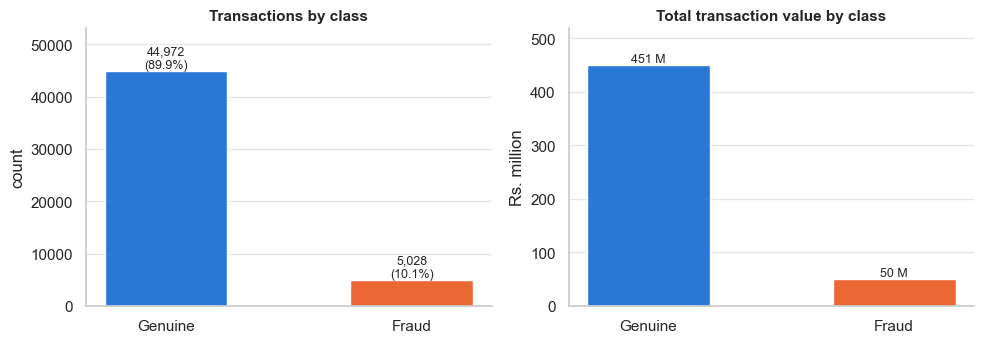

Fraud is 10.06% of transactions and about Rs. 50.0 million of value in 3 months.
Average fraud amount: 9,944 | average genuine amount: 10,023


In [14]:
overall = df.is_fraud.mean()
counts = df.is_fraud.value_counts()
fraud_amount = df.loc[df.is_fraud == 1, "amount"].sum()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(["Genuine", "Fraud"], counts.values, color=[BLUE, ORANGE], width=0.5)
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
ax[0].set_title("Transactions by class"); ax[0].set_ylim(0, counts.max() * 1.18); ax[0].set_ylabel("count")

amt_by_class = df.groupby("is_fraud").amount.sum() / 1e6
ax[1].bar(["Genuine", "Fraud"], amt_by_class.values, color=[BLUE, ORANGE], width=0.5)
for i, v in enumerate(amt_by_class.values):
    ax[1].text(i, v, f"{v:,.0f} M", ha="center", va="bottom", fontsize=9)
ax[1].set_title("Total transaction value by class"); ax[1].set_ylim(0, amt_by_class.max() * 1.15); ax[1].set_ylabel("Rs. million")
plt.tight_layout(); plt.show()
print(f"Fraud is {overall:.2%} of transactions and about Rs. {fraud_amount/1e6:,.1f} million of value in 3 months.")
print("Average fraud amount: {:,.0f} | average genuine amount: {:,.0f}".format(
    df.loc[df.is_fraud == 1, "amount"].mean(), df.loc[df.is_fraud == 0, "amount"].mean()))

Roughly 1 in 10 transactions is fraud, so accuracy is a useless metric here. A model that says "genuine" every time would be
90% accurate and catch zero fraud. I will use PR-AUC, ROC-AUC, recall/precision and cost instead.

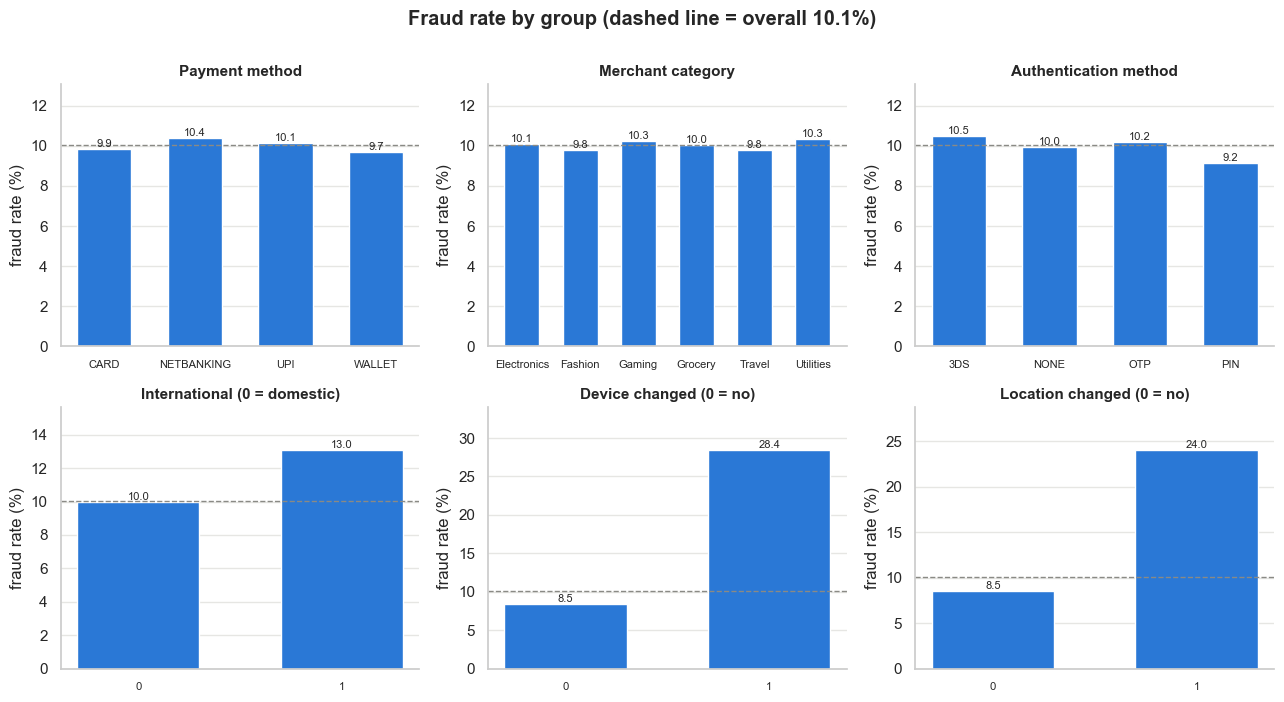

In [15]:
# fraud rate for each category-like column
def rate_bar(col, ax, order=None, title=None):
    r = df.groupby(col).is_fraud.mean().mul(100)
    if order is not None:
        r = r.reindex(order)
    ax.bar(r.index.astype(str), r.values, color=BLUE, width=0.6)
    ax.axhline(overall * 100, color=GREY, ls="--", lw=1)
    for i, v in enumerate(r.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title or col); ax.set_ylabel("fraud rate (%)"); ax.set_xlabel("")
    ax.set_ylim(0, max(r.values.max() * 1.2, overall * 130))
    ax.tick_params(axis="x", labelsize=8)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
rate_bar("payment_method", axes[0, 0], title="Payment method")
rate_bar("merchant_category", axes[0, 1], title="Merchant category")
rate_bar("authentication_method", axes[0, 2], title="Authentication method")
rate_bar("is_international", axes[1, 0], title="International (0 = domestic)")
rate_bar("device_change_flag", axes[1, 1], title="Device changed (0 = no)")
rate_bar("location_change_flag", axes[1, 2], title="Location changed (0 = no)")
fig.suptitle("Fraud rate by group (dashed line = overall {:.1f}%)".format(overall * 100), y=1.0, fontweight="bold")
plt.tight_layout(); plt.show()

Payment method, merchant category and authentication method are all more or less flat around the overall rate. The
usual assumption is that travel / gaming / electronics are riskier, but in this data they are not. The three that stand out are:

* **device change**: 28.4% fraud when the device changed vs 8.5% when it did not, about 3.4 times higher,
* **location change**: 24.0% vs 8.5%, about 2.8 times higher,
* international: 13.0% vs 10.0%, a smaller bump (and only 3% of transactions are international).

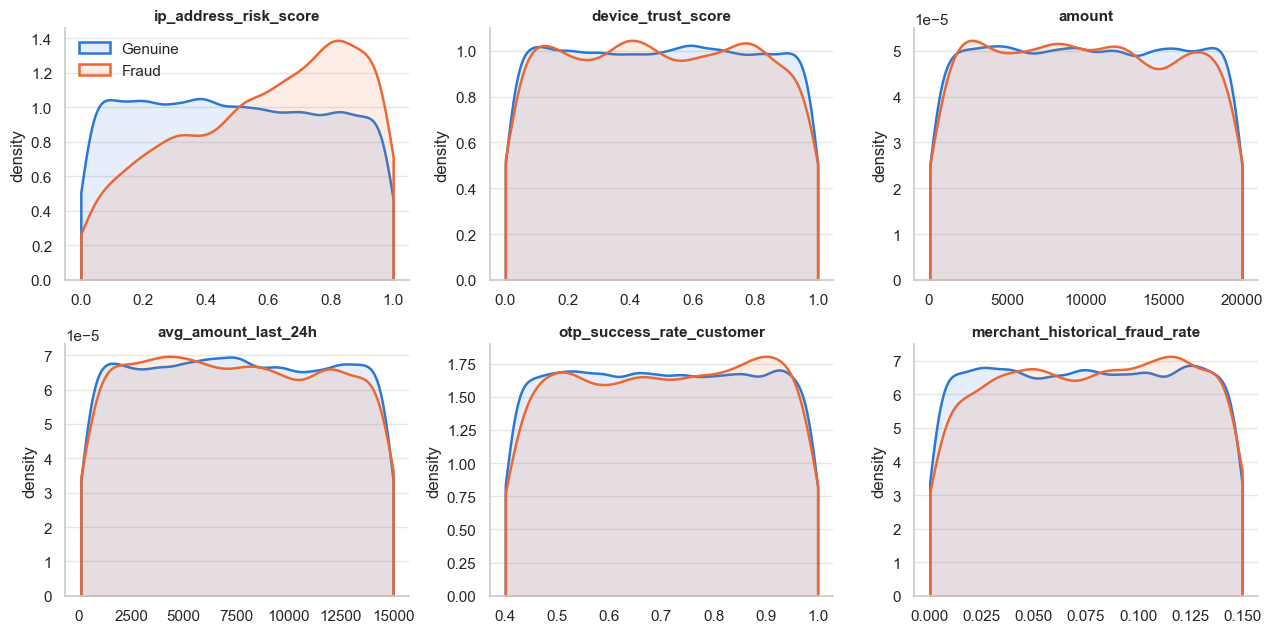

In [16]:
# numeric columns, distributions for genuine vs fraud
num_plot = ["ip_address_risk_score", "device_trust_score", "amount", "avg_amount_last_24h",
            "otp_success_rate_customer", "merchant_historical_fraud_rate"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), num_plot):
    for k, name in [(0, "Genuine"), (1, "Fraud")]:
        sns.kdeplot(df.loc[df.is_fraud == k, c].dropna(), ax=ax, color=PAL[k], label=name, lw=1.8, fill=True, alpha=0.12, cut=0)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("density")
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

Only `ip_address_risk_score` shows a visible shift: the fraud curve leans to the right (higher IP risk). The other
curves almost sit on top of each other. Notably, `device_trust_score` and `amount` do not separate the classes at all, even though
common fraud heuristics expect them to. Let me look at the IP risk more closely, split into 10 equal-sized groups (deciles).

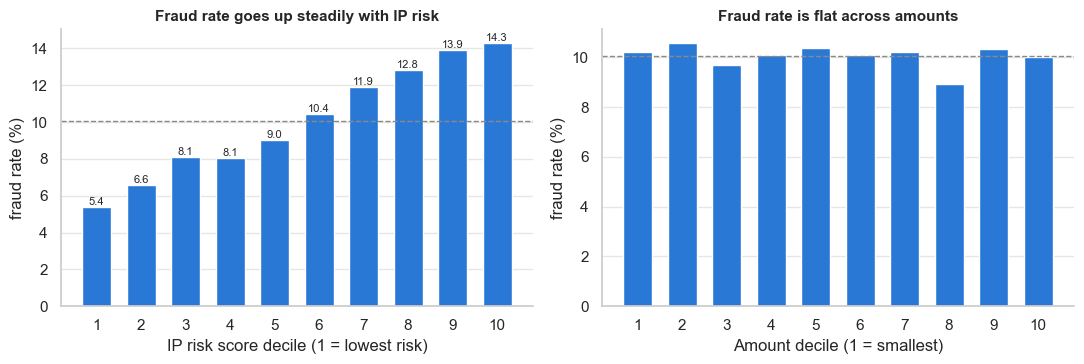

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
dec = df.groupby(pd.qcut(df.ip_address_risk_score, 10), observed=True).is_fraud.mean().mul(100)
ax[0].bar(range(1, 11), dec.values, color=BLUE, width=0.65)
ax[0].axhline(overall * 100, color=GREY, ls="--", lw=1)
ax[0].set_xticks(range(1, 11)); ax[0].set_xlabel("IP risk score decile (1 = lowest risk)"); ax[0].set_ylabel("fraud rate (%)")
ax[0].set_title("Fraud rate goes up steadily with IP risk")
for i, v in enumerate(dec.values):
    ax[0].text(i + 1, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)

dec2 = df.groupby(pd.qcut(df.amount, 10), observed=True).is_fraud.mean().mul(100)
ax[1].bar(range(1, 11), dec2.values, color=BLUE, width=0.65)
ax[1].axhline(overall * 100, color=GREY, ls="--", lw=1)
ax[1].set_xticks(range(1, 11)); ax[1].set_xlabel("Amount decile (1 = smallest)"); ax[1].set_ylabel("fraud rate (%)")
ax[1].set_title("Fraud rate is flat across amounts")
plt.tight_layout(); plt.show()

IP risk works like a proper risk score: the top decile has about 14.3% fraud and the bottom decile about 5.4%, roughly 2.6 times
difference. Amount is flat, so large transactions are not more likely to be fraud in this data. (Large ones still cost
more when they *are* fraud, so amount still matters for the cost side, just not for the probability.)

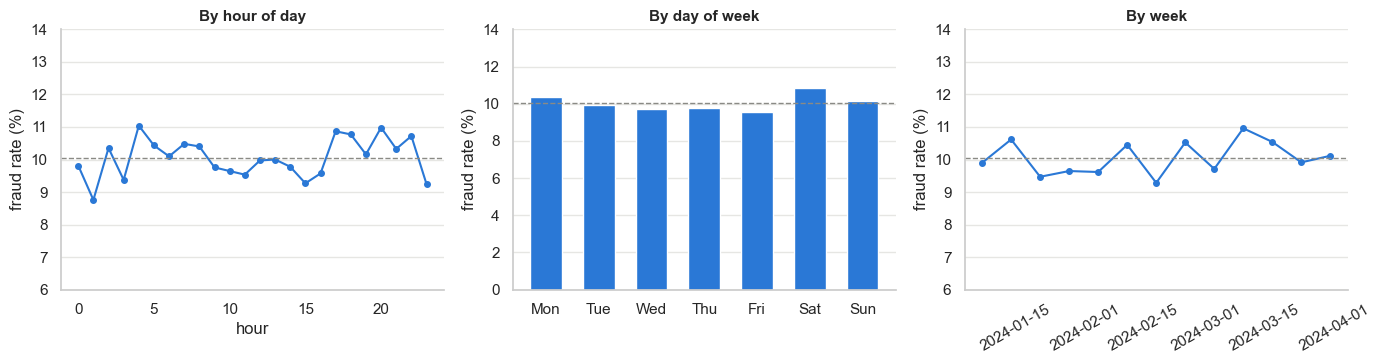

In [18]:
# time patterns
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
h = df.groupby("hour_of_day").is_fraud.mean().mul(100)
axes[0].plot(h.index, h.values, color=BLUE, marker="o", ms=4, lw=1.5)
axes[0].axhline(overall * 100, color=GREY, ls="--", lw=1)
axes[0].set_title("By hour of day"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("fraud rate (%)"); axes[0].set_ylim(6, 14)

d = df.groupby("day_of_week").is_fraud.mean().mul(100)
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], d.values, color=BLUE, width=0.6)
axes[1].axhline(overall * 100, color=GREY, ls="--", lw=1)
axes[1].set_title("By day of week"); axes[1].set_ylabel("fraud rate (%)"); axes[1].set_ylim(0, 14)

wk = df.set_index("ts").is_fraud.resample("W").mean().mul(100)
axes[2].plot(wk.index, wk.values, color=BLUE, marker="o", ms=4, lw=1.5)
axes[2].axhline(overall * 100, color=GREY, ls="--", lw=1)
axes[2].set_title("By week"); axes[2].set_ylabel("fraud rate (%)"); axes[2].set_ylim(6, 14)
axes[2].tick_params(axis="x", labelrotation=30)
plt.tight_layout(); plt.show()

No real late-night spike and no clear weekend effect. The hourly line wiggles between about 8.8% and 11% which is just noise for
groups of ~2,000 transactions. The weekly rate is stable (~9.3% to 11%), so the fraud rate isn't drifting during these
3 months. Good to know for the time-based split later.

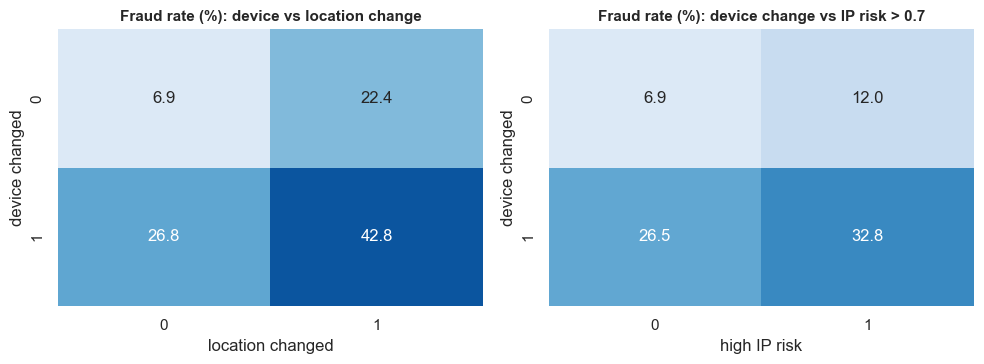

Both device AND location changed: 388 transactions (0.8%) with 42.8% fraud
Neither changed: 82.9% of transactions with 6.9% fraud


In [19]:
# combined effect of device and location change, and of device change and high IP risk
df["_ip_high"] = (df.ip_address_risk_score > 0.7).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
p1 = df.pivot_table(index="device_change_flag", columns="location_change_flag", values="is_fraud", aggfunc="mean").mul(100)
p2 = df.pivot_table(index="device_change_flag", columns="_ip_high", values="is_fraud", aggfunc="mean").mul(100)
sns.heatmap(p1, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax[0], vmin=0, vmax=50)
ax[0].set_title("Fraud rate (%): device vs location change"); ax[0].set_xlabel("location changed"); ax[0].set_ylabel("device changed")
sns.heatmap(p2, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax[1], vmin=0, vmax=50)
ax[1].set_title("Fraud rate (%): device change vs IP risk > 0.7"); ax[1].set_xlabel("high IP risk"); ax[1].set_ylabel("device changed")
plt.tight_layout(); plt.show()
df.drop(columns="_ip_high", inplace=True)

both = df[(df.device_change_flag == 1) & (df.location_change_flag == 1)]
print(f"Both device AND location changed: {len(both)} transactions ({len(both)/len(df):.1%}) with {both.is_fraud.mean():.1%} fraud")
print(f"Neither changed: {((df.device_change_flag==0)&(df.location_change_flag==0)).mean():.1%} of transactions with "
      f"{df[(df.device_change_flag==0)&(df.location_change_flag==0)].is_fraud.mean():.1%} fraud")

The signals add up: when nothing changed the fraud rate is 6.9%, when both device and location changed it goes to 42.8%.
But those "both changed" cases are less than 1% of all transactions (388 out of 50,000), so they can only catch a small slice of
the fraud. Another thing to keep in mind is that **more than half of all fraud happens with no device or
location change**, and looks like a normal transaction. That will limit how good any model can get on this data.

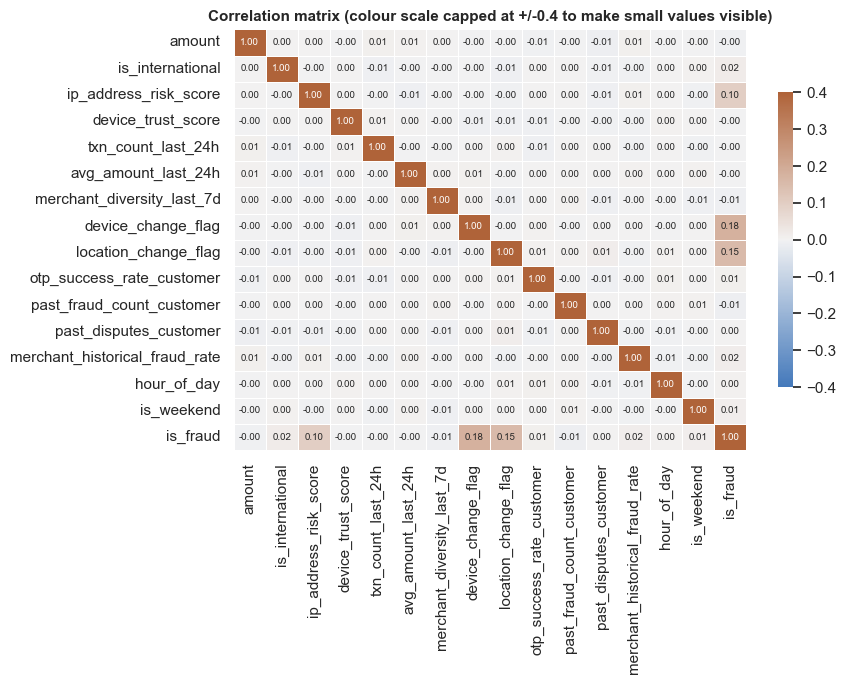

device_change_flag                0.179
location_change_flag              0.153
ip_address_risk_score             0.097
is_international                  0.017
merchant_historical_fraud_rate    0.015
is_weekend                        0.010
otp_success_rate_customer         0.009
hour_of_day                       0.004
past_disputes_customer            0.001
txn_count_last_24h               -0.001
device_trust_score               -0.003
avg_amount_last_24h              -0.003
amount                           -0.004
merchant_diversity_last_7d       -0.007
past_fraud_count_customer        -0.010
Name: is_fraud, dtype: float64


In [20]:
# correlation heatmap, numeric columns only (IDs left out)
corr_cols = ["amount", "is_international", "ip_address_risk_score", "device_trust_score", "txn_count_last_24h",
             "avg_amount_last_24h", "merchant_diversity_last_7d", "device_change_flag", "location_change_flag",
             "otp_success_rate_customer", "past_fraud_count_customer", "past_disputes_customer",
             "merchant_historical_fraud_rate", "hour_of_day", "is_weekend", "is_fraud"]
cm = df[corr_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(cm, cmap=sns.diverging_palette(250, 30, as_cmap=True), center=0, vmin=-0.4, vmax=0.4,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (colour scale capped at +/-0.4 to make small values visible)")
plt.tight_layout(); plt.show()
print(cm["is_fraud"].drop("is_fraud").sort_values(ascending=False).round(3))

The features are basically uncorrelated with each other, so multicollinearity is not a concern. Only 3 columns have a
noticeable correlation with fraud: `device_change_flag` (0.18), `location_change_flag` (0.15) and `ip_address_risk_score` (0.10).
Everything else is within +/-0.02 of zero.

### 4.1 Statistical tests

Charts can fool me, so I test each column against `is_fraud`.

* Categorical / binary columns: **chi-square test of independence**, with Cramer's V as effect size (0 = no link, 1 = perfect link).
* Numeric columns: **Mann-Whitney U test** (fraud vs genuine), because most of these are not normally distributed. Effect size is
  |2 x AUC - 1|, which is 0 for no separation and 1 for perfect separation.

H0: the column has no relationship with fraud. With 50,000 rows even tiny differences can give a small p-value, so I also look at
effect size, and I use a Bonferroni-corrected significance level because I am running many tests at once.

In [21]:
cat_tests = ["payment_method", "merchant_category", "authentication_method", "is_international", "device_change_flag",
             "location_change_flag", "is_weekend", "day_of_week", "hour_of_day", "past_fraud_count_customer", "past_disputes_customer"]
num_tests = ["amount", "ip_address_risk_score", "device_trust_score", "txn_count_last_24h", "avg_amount_last_24h",
             "merchant_diversity_last_7d", "otp_success_rate_customer", "merchant_historical_fraud_rate"]

rows = []
for c in cat_tests:
    ct = pd.crosstab(df[c], df.is_fraud)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append({"column": c, "test": "chi-square", "p_value": p, "effect_size": v})

f, g = df[df.is_fraud == 1], df[df.is_fraud == 0]
for c in num_tests:
    a, b = f[c].dropna(), g[c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    auc = u / (len(a) * len(b))
    rows.append({"column": c, "test": "Mann-Whitney", "p_value": p, "effect_size": abs(2 * auc - 1)})

tests = pd.DataFrame(rows)
alpha = 0.05 / len(tests)
tests["significant (Bonferroni)"] = np.where(tests.p_value < alpha, "yes", "no")
tests = tests.sort_values("effect_size", ascending=False).reset_index(drop=True)
print(f"Bonferroni corrected alpha = 0.05 / {len(tests)} = {alpha:.4f}")
tests.style.format({"p_value": "{:.2e}", "effect_size": "{:.3f}"})

Bonferroni corrected alpha = 0.05 / 19 = 0.0026


,column,test,p_value,effect_size,significant (Bonferroni)
0,ip_address_risk_score,Mann-Whitney,1.39e-104,0.186,yes
1,device_change_flag,chi-square,0.00e+00,0.179,yes
2,location_change_flag,chi-square,4.82e-257,0.153,yes
3,merchant_historical_fraud_rate,Mann-Whitney,7.59e-04,0.029,yes
4,hour_of_day,chi-square,6.91e-01,0.020,no
5,otp_success_rate_customer,Mann-Whitney,3.67e-02,0.018,no
6,is_international,chi-square,1.22e-04,0.017,yes
7,day_of_week,chi-square,1.39e-01,0.014,no
8,authentication_method,chi-square,3.13e-02,0.013,no
9,merchant_diversity_last_7d,Mann-Whitney,1.23e-01,0.013,no


The tests agree with the charts. Five columns pass the corrected significance level, but they are not equally important:

* `ip_address_risk_score`, `device_change_flag` and `location_change_flag` have real effect sizes (0.15 to 0.19).
* `merchant_historical_fraud_rate` and `is_international` are "significant" only because I have 50,000 rows; their effect sizes are
  tiny (0.03 and 0.02), which is exactly the case where the p-value alone would mislead me.
* Everything else (amount, weekend / day / hour, payment method, category, authentication method, device trust score, velocity,
  customer history) has no significant relationship with fraud and an effect size close to 0.

So the usual fraud heuristics (weekend, late night, high amounts, device trust, category risk) have **no support in this dataset**. I still test some
of them as engineered features later, because a feature can be weak on its own and useful in combination, and I want to show that with evidence.

## 5. Feature engineering

I build features from the standard fraud-detection playbook, grouped by theme. There are two kinds of features:

* **Row-level features**: can be computed from a single transaction record. These are easy to deploy in a real-time
  gateway because nothing else has to be looked up.
* **History features**: need the customer's earlier transactions (velocity, "seen this device before" etc.). I calculate these using only
  *earlier* rows, so there is no peeking into the future.

For every feature I write down why I think it might matter. Then in the modelling section I test whether it actually helps.

In [22]:
def add_features(d):
    """Row-level features. Only uses the transaction's own columns, so it can run at scoring time."""
    d = d.copy()

    # --- time features ---
    d["is_night"] = d.hour_of_day.isin([0, 1, 2, 3, 4, 5]).astype(int)          # customers less likely to watch alerts at night
    d["hour_sin"] = np.sin(2 * np.pi * d.hour_of_day / 24)                       # 23:00 and 00:00 are close, a plain number hides that
    d["hour_cos"] = np.cos(2 * np.pi * d.hour_of_day / 24)
    d["time_bucket"] = pd.cut(d.hour_of_day, [-1, 5, 11, 17, 23], labels=["night", "morning", "afternoon", "evening"]).astype(str)

    # --- amount features ---
    d["log_amount"] = np.log1p(d.amount)
    d["amount_bucket"] = pd.cut(d.amount, [0, 7000, 14000, 20001], labels=["low", "medium", "high"]).astype(str)
    d["amount_to_avg_ratio"] = d.amount / d.avg_amount_last_24h                  # NaN when there was no activity, imputed later
    d["amount_minus_avg"] = d.amount - d.avg_amount_last_24h
    d["amount_spike"] = (d.amount_to_avg_ratio > 3).astype(int)                  # 3x the recent average = unusual

    # --- velocity features ---
    d["no_recent_activity"] = (d.txn_count_last_24h == 0).astype(int)
    d["high_velocity"] = (d.txn_count_last_24h >= 8).astype(int)                 # 8+ in a day is in the top ~33%
    d["est_spend_24h"] = (d.txn_count_last_24h * d.avg_amount_last_24h).fillna(0)

    # --- device / identity consistency ---
    d["identity_change_count"] = d.device_change_flag + d.location_change_flag
    d["both_changed"] = ((d.device_change_flag == 1) & (d.location_change_flag == 1)).astype(int)
    d["low_device_trust"] = (d.device_trust_score < 0.3).astype(int)
    d["new_device_low_trust"] = ((d.device_change_flag == 1) & (d.low_device_trust == 1)).astype(int)

    # --- network ---
    d["high_ip_risk"] = (d.ip_address_risk_score > 0.7).astype(int)

    # --- merchant / category ---
    d["high_risk_category"] = d.merchant_category.isin(["Gaming", "Travel", "Electronics"]).astype(int)   # commonly assumed risky categories
    d["merchant_risk_level"] = pd.cut(d.merchant_historical_fraud_rate, [-0.001, 0.05, 0.10, 0.15],
                                      labels=["low", "medium", "high"]).astype(str)

    # --- payment method / authentication ---
    d["no_auth"] = (d.authentication_method == "NONE").astype(int)
    d["intl_weak_auth"] = ((d.is_international == 1) & d.authentication_method.isin(["NONE", "PIN"])).astype(int)

    # --- customer profile ---
    d["prior_incidents"] = d.past_fraud_count_customer + d.past_disputes_customer
    d["low_otp_success"] = (d.otp_success_rate_customer < 0.5).astype(int)

    # --- combined risk index ---
    # Hand-set weights: bigger weight for the signals that looked strongest in EDA (IP risk, device change, location change),
    # small weights for the softer heuristics. Scaled 0-100.
    d["combined_risk_index"] = 100 * (0.30 * d.ip_address_risk_score + 0.25 * d.device_change_flag
                                      + 0.20 * d.location_change_flag + 0.10 * (1 - d.device_trust_score)
                                      + 0.05 * d.merchant_historical_fraud_rate / 0.15 + 0.05 * d.is_international
                                      + 0.05 * d.no_auth)
    return d


def add_history_features(d):
    """History features. Needs the data sorted by time. Uses only earlier rows of the same customer/device."""
    d = d.copy()
    g = d.groupby("customer_id")
    d["cust_txn_so_far"] = g.cumcount()                                                    # how many earlier txns the customer has
    d["secs_since_last_txn"] = g["ts"].diff().dt.total_seconds()                           # gap since the previous one
    d["rapid_repeat_1h"] = (d.secs_since_last_txn <= 3600).astype(int)                     # 1h velocity proxy
    d["device_seen_before"] = (d.groupby(["customer_id", "device_id"]).cumcount() > 0).astype(int)
    d["merchant_seen_before"] = (d.groupby(["customer_id", "merchant_id"]).cumcount() > 0).astype(int)
    d["amt_vs_cust_history"] = d.amount / g["amount"].transform(lambda s: s.shift().expanding().mean())
    d["cust_prior_fraud_rate"] = g["is_fraud"].transform(lambda s: s.shift().expanding().mean())
    first_pair = (~d.duplicated(["device_id", "customer_id"])).astype(int)
    d["device_customers_so_far"] = first_pair.groupby(d.device_id).cumsum()                # device sharing across accounts
    d["cust_devices_so_far"] = first_pair.groupby(d.customer_id).cumsum()
    return d


feat = add_history_features(add_features(df))
print(feat.shape)
feat.head(3).T.tail(38)

(50000, 59)


,0,1,2
hour_of_day,0,0,0
day_of_week,0,0,0
is_weekend,0,0,0
is_fraud,1,0,0
ts,2024-01-01 00:01:00,2024-01-01 00:04:00,2024-01-01 00:06:00
is_night,1,1,1
hour_sin,0.0,0.0,0.0
hour_cos,1.0,1.0,1.0
time_bucket,night,night,night
log_amount,9.880138,9.548933,7.711697


### 5.1 Chronological split

I split by **time**, not randomly: oldest 70% of transactions for training, the next 15% for validation (model selection and
threshold tuning), and the newest 15% for the final test. In real life the model is trained on the past and used on the
future, and fraud patterns move around. A random split would let the model see transactions from the same period it is tested on, and
the score would look better than it really is. The test set stays untouched until the final evaluation.

In [23]:
n = len(feat)
i_tr, i_va = int(0.70 * n), int(0.85 * n)
train, valid, test = feat.iloc[:i_tr].copy(), feat.iloc[i_tr:i_va].copy(), feat.iloc[i_va:].copy()

split_info = pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "from": [x.ts.min().date() for x in (train, valid, test)],
    "to": [x.ts.max().date() for x in (train, valid, test)],
    "fraud_count": [x.is_fraud.sum() for x in (train, valid, test)],
    "fraud_rate": [f"{x.is_fraud.mean():.2%}" for x in (train, valid, test)],
}, index=["train", "validation", "test"])
split_info

,rows,from,to,fraud_count,fraud_rate
train,35000,2024-01-01,2024-03-03,3472,9.92%
validation,7500,2024-03-03,2024-03-17,800,10.67%
test,7500,2024-03-17,2024-03-30,756,10.08%


The fraud rate is about the same in all three parts (~10%), so no big drift, and each part has hundreds of fraud cases.

### 5.2 Does each feature carry any signal?

Quick check on the **training set only**: for each numeric feature, the AUC when I use that single feature as a score
(0.5 = no better than random; further from 0.5 in either direction = more useful).

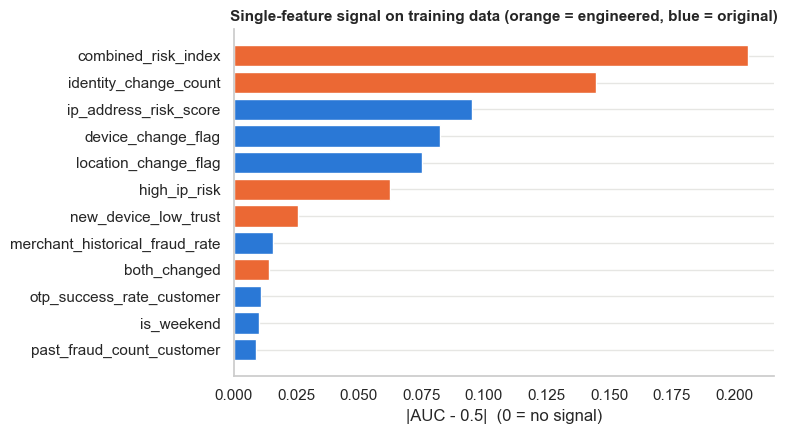

,feature,type,AUC,distance_from_0.5
0,combined_risk_index,engineered,0.706,0.206
1,identity_change_count,engineered,0.645,0.145
2,ip_address_risk_score,raw,0.595,0.095
3,device_change_flag,raw,0.582,0.082
4,location_change_flag,raw,0.575,0.075
5,high_ip_risk,engineered,0.562,0.062
6,new_device_low_trust,engineered,0.526,0.026
7,merchant_historical_fraud_rate,raw,0.516,0.016
8,both_changed,engineered,0.514,0.014
9,otp_success_rate_customer,raw,0.511,0.011


In [24]:
raw_num = ["amount", "is_international", "ip_address_risk_score", "device_trust_score", "txn_count_last_24h",
           "avg_amount_last_24h", "merchant_diversity_last_7d", "device_change_flag", "location_change_flag",
           "otp_success_rate_customer", "past_fraud_count_customer", "past_disputes_customer",
           "merchant_historical_fraud_rate", "hour_of_day", "day_of_week", "is_weekend"]
raw_cat = ["payment_method", "merchant_category", "authentication_method"]

FEATURE_GROUPS = {   # (numeric, categorical) for each group, used later for the ablation test
    "time": (["is_night", "hour_sin", "hour_cos"], ["time_bucket"]),
    "amount": (["log_amount", "amount_to_avg_ratio", "amount_minus_avg", "amount_spike"], ["amount_bucket"]),
    "velocity": (["no_recent_activity", "high_velocity", "est_spend_24h"], []),
    "identity": (["identity_change_count", "both_changed", "low_device_trust", "new_device_low_trust"], []),
    "network": (["high_ip_risk"], []),
    "merchant": (["high_risk_category"], ["merchant_risk_level"]),
    "payment": (["no_auth", "intl_weak_auth"], []),
    "customer": (["prior_incidents", "low_otp_success"], []),
    "combined": (["combined_risk_index"], []),
}
history_num = ["cust_txn_so_far", "secs_since_last_txn", "rapid_repeat_1h", "device_seen_before", "merchant_seen_before",
               "amt_vs_cust_history", "cust_prior_fraud_rate", "device_customers_so_far", "cust_devices_so_far"]

all_num = raw_num + [c for g in FEATURE_GROUPS.values() for c in g[0]] + history_num
kind = {c: "raw" for c in raw_num}
kind.update({c: "engineered" for g in FEATURE_GROUPS.values() for c in g[0]})
kind.update({c: "history" for c in history_num})

uni = []
for c in all_num:
    x = train[c].fillna(train[c].median())
    a = roc_auc_score(train.is_fraud, x)
    uni.append({"feature": c, "type": kind[c], "AUC": a, "distance_from_0.5": abs(a - 0.5)})
uni = pd.DataFrame(uni).sort_values("distance_from_0.5", ascending=False).reset_index(drop=True)

top = uni.head(12).iloc[::-1]
plt.figure(figsize=(8, 4.5))
plt.barh(top.feature, top["distance_from_0.5"], color=[ORANGE if t != "raw" else BLUE for t in top.type])
plt.xlabel("|AUC - 0.5|  (0 = no signal)"); plt.title("Single-feature signal on training data (orange = engineered, blue = original)")
plt.tight_layout(); plt.show()
uni.head(15).round(3)

The strongest features are the original three (`device_change_flag`, `location_change_flag`, `ip_address_risk_score`) and
the engineered features that are built out of them (`combined_risk_index`, `identity_change_count`, `high_ip_risk`).
That makes sense: the engineered ones are basically the same information, rescaled or added together, so they are not new signals.

The **history features** (velocity, "device seen before", "merchant seen before", customer's earlier fraud rate) and the
amount features are all at about AUC 0.50. Let me look at them directly, since fraud playbooks put a lot of weight on them.

In [25]:
uni[uni.type == "history"].round(3).reset_index(drop=True)

,feature,type,AUC,distance_from_0.5
0,cust_prior_fraud_rate,history,0.509,0.009
1,cust_devices_so_far,history,0.508,0.008
2,cust_txn_so_far,history,0.508,0.008
3,amt_vs_cust_history,history,0.494,0.006
4,secs_since_last_txn,history,0.494,0.006
5,device_customers_so_far,history,0.495,0.005
6,merchant_seen_before,history,0.500,0.000
7,device_seen_before,history,0.500,0.000
8,rapid_repeat_1h,history,0.500,0.000


In [26]:
# device familiarity in this data: how often is a (customer, device) pair seen for the first time?
print("share of transactions on a device the customer has NOT used before:", round(1 - feat.device_seen_before.mean(), 4))
print("share on a merchant the customer has not used before:", round(1 - feat.merchant_seen_before.mean(), 3))
print("share with another txn by the same customer in the previous hour:", round(feat.rapid_repeat_1h.mean(), 4))

share of transactions on a device the customer has NOT used before: 0.9994
share on a merchant the customer has not used before: 0.98
share with another txn by the same customer in the previous hour: 0.0059


Why the history features don't work here:

* 99.9% of transactions are on a device that customer never used before (device IDs are basically random per customer), so
  "device familiarity" has nothing to measure. That is also why the given `device_change_flag` is the better signal.
* A customer has only ~12 transactions in 3 months, so there is not much history, and "another transaction in the last hour" happens in less
  than 1% of rows, so 1-hour velocity is too sparse to be useful.

I keep them as candidates and test them properly in the ablation (section 7.5). If they do not help, I leave them out, which
also keeps the model simple to run in real time (no customer history lookup needed).

### 5.3 Behavioural anomaly score (unsupervised)

Anomaly scores are a common fraud signal. I try an Isolation Forest, which scores how "unusual" a transaction is across several behaviour
columns without using the fraud label. It is fitted on the training data only.

In [27]:
beh_cols = ["log_amount", "amount_to_avg_ratio", "txn_count_last_24h", "merchant_diversity_last_7d",
            "device_trust_score", "ip_address_risk_score", "otp_success_rate_customer"]
med = train[beh_cols].median()
iso = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1).fit(train[beh_cols].fillna(med))
for name, part in [("train", train), ("validation", valid)]:
    score = -iso.score_samples(part[beh_cols].fillna(med))       # higher = more unusual
    print(f"{name}: anomaly score AUC vs fraud = {roc_auc_score(part.is_fraud, score):.3f}")

train: anomaly score AUC vs fraud = 0.502
validation: anomaly score AUC vs fraud = 0.517


The anomaly score has an AUC of about 0.5, so being "statistically unusual" across these columns does not mean "fraud" here. Genuine
and fraud transactions look equally unusual. This is consistent with everything else so far, so I leave the anomaly score out of the final
model (it would also need to be saved and served as an extra model at scoring time).

**Check on the combined risk index.** It is a hand-picked weighted mix of signals, no model involved. Since I picked the weights
after seeing the EDA it might look optimistic, so I check it on the validation data only, as a simple benchmark for later.

In [28]:
print("Combined risk index, validation AUC:", round(roc_auc_score(valid.is_fraud, valid.combined_risk_index), 3),
      "| PR-AUC:", round(average_precision_score(valid.is_fraud, valid.combined_risk_index), 3))

Combined risk index, validation AUC: 0.685 | PR-AUC: 0.212


## 6. Preparing the data for modelling

What I do here and why:

* **Drop the ID columns** (`transaction_id`, `customer_id`, `device_id`, `merchant_id`) and the raw `timestamp`. IDs are just labels; a model that
  memorises them would not work for a new customer. (I also showed above that IDs have no signal.)
* **One-hot encode** the categorical columns.
* **Impute** the missing `amount_to_avg_ratio` / `amount_minus_avg` (from the no-activity rows) using the median of the training data. There is a
  `no_recent_activity` flag next to them, so the model still knows that the value was missing.
* **Scale** numeric columns for logistic regression only (trees do not care).
* Everything goes in a scikit-learn `Pipeline`, so the imputer / scaler / encoder are fitted on the training part only. This avoids leakage
  from validation and test data.

In [29]:
def make_preprocessor(num_cols, cat_cols, scale):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    parts = [("num", Pipeline(num_steps), list(num_cols))]
    if len(cat_cols) > 0:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols)))
    return ColumnTransformer(parts)


def features_for(groups):
    """numeric + categorical column lists for the raw features plus the chosen engineered groups"""
    num, cat = list(raw_num), list(raw_cat)
    for gname in groups:
        if gname == "history":
            num += history_num
        else:
            num += FEATURE_GROUPS[gname][0]
            cat += FEATURE_GROUPS[gname][1]
    return num, cat


def make_models(class_weight=None):
    """the models I compare. Second item = whether numeric inputs should be scaled"""
    return {
        "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight=class_weight), True),
        "Decision Tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=100, class_weight=class_weight, random_state=SEED), False),
        "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=50, n_jobs=-1,
                                                 class_weight="balanced_subsample" if class_weight else None, random_state=SEED), False),
        "Hist. Gradient Boosting": (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                                                   class_weight=class_weight, random_state=SEED), False),
    }


def build_pipe(model, num, cat, scale):
    return Pipeline([("prep", make_preprocessor(num, cat, scale)), ("model", model)])


# metrics that do not depend on a threshold + one that mimics a fixed review capacity
def score_all(y, p, review_frac=0.20):
    y, p = np.asarray(y), np.asarray(p)
    k = int(len(y) * review_frac)
    top_idx = np.argsort(-p)[:k]
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            f"recall@top{int(review_frac*100)}%": y[top_idx].sum() / y.sum(),
            f"precision@top{int(review_frac*100)}%": y[top_idx].mean()}


y_train, y_valid, y_test = train.is_fraud, valid.is_fraud, test.is_fraud
BASE_NUM, BASE_CAT = features_for([])
ALL_GROUPS = list(FEATURE_GROUPS.keys())          # all row-level engineered groups (history not included)
ENG_NUM, ENG_CAT = features_for(ALL_GROUPS)
print("raw features:", len(BASE_NUM) + len(BASE_CAT), "| raw + engineered:", len(ENG_NUM) + len(ENG_CAT))

raw features: 19 | raw + engineered: 43


## 7. Modelling

### 7.1 Baselines

Before any real model I want to know what "doing nothing clever" scores, otherwise I can't tell if a model is good.
* **Random / prior**: a model that just predicts the fraud rate for everybody (PR-AUC equals the base rate).
* **Simple rule**: flag if the device changed OR the location changed.
* **Combined risk index** (from section 5).

In [30]:
base_rate = y_valid.mean()
rule_score = ((valid.device_change_flag == 1) | (valid.location_change_flag == 1)).astype(int)
tp = ((rule_score == 1) & (y_valid == 1)).sum()
print(f"Base rate in validation: {base_rate:.3f}  (random flagging gives PR-AUC = {base_rate:.3f} and ROC-AUC = 0.5)")
print(f"Rule 'device OR location changed': flags {rule_score.mean():.1%} of transactions, "
      f"precision {tp/rule_score.sum():.1%}, recall {tp/y_valid.sum():.1%}")

baselines = pd.DataFrame({
    "Random guess": {"ROC-AUC": 0.5, "PR-AUC": base_rate, "recall@top20%": 0.20, "precision@top20%": base_rate},
    "Combined risk index": score_all(y_valid, valid.combined_risk_index),
}).T
baselines.round(3)

Base rate in validation: 0.107  (random flagging gives PR-AUC = 0.107 and ROC-AUC = 0.5)
Rule 'device OR location changed': flags 17.9% of transactions, precision 24.9%, recall 41.9%


,ROC-AUC,PR-AUC,recall@top20%,precision@top20%
Random guess,0.500,0.107,0.200,0.107
Combined risk index,0.685,0.212,0.414,0.221


### 7.2 Handling class imbalance

Fraud is ~10% of the data. I compare four ways of handling it, using the same features, fitting on the training set only and
scoring on the validation set:

1. **Nothing** (normal training)
2. **Class weights** (algorithmic): errors on fraud count more, roughly 9 times
3. **Random oversampling** of fraud rows in the training data until the classes are balanced
4. **Random undersampling** of genuine rows

I could not use SMOTE because the `imbalanced-learn` package is not installed here, and random resampling is fine to show the idea
(SMOTE is listed under future work). Resampling is applied to the training data only, never validation/test.

In [31]:
def resample_train(X, y, how, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y.values == 1)[0], np.where(y.values == 0)[0]
    if how == "over":
        pos = rng.choice(pos, size=len(neg), replace=True)
    elif how == "under":
        neg = rng.choice(neg, size=len(pos), replace=False)
    idx = np.concatenate([pos, neg]); rng.shuffle(idx)
    return X.iloc[idx], y.iloc[idx]


strategies = {"none": (None, None), "class weight": ("balanced", None), "oversample": (None, "over"), "undersample": (None, "under")}
X_tr, X_va = train, valid
imb_rows = []
for mname in ["Logistic Regression", "Hist. Gradient Boosting", "Random Forest"]:
    for sname, (cw, how) in strategies.items():
        model, scale = make_models(cw)[mname]
        Xf, yf = (X_tr, y_train) if how is None else resample_train(X_tr, y_train, how)
        pipe = build_pipe(model, ENG_NUM, ENG_CAT, scale).fit(Xf, yf)
        s = score_all(y_valid, pipe.predict_proba(X_va)[:, 1])
        imb_rows.append({"model": mname, "strategy": sname, **s})
imb = pd.DataFrame(imb_rows)
imb.pivot(index="model", columns="strategy", values="PR-AUC").round(3)

strategy,class weight,none,oversample,undersample
model,,,,
Hist. Gradient Boosting,0.221,0.223,0.218,0.220
Logistic Regression,0.221,0.222,0.222,0.219
Random Forest,0.220,0.218,0.219,0.227


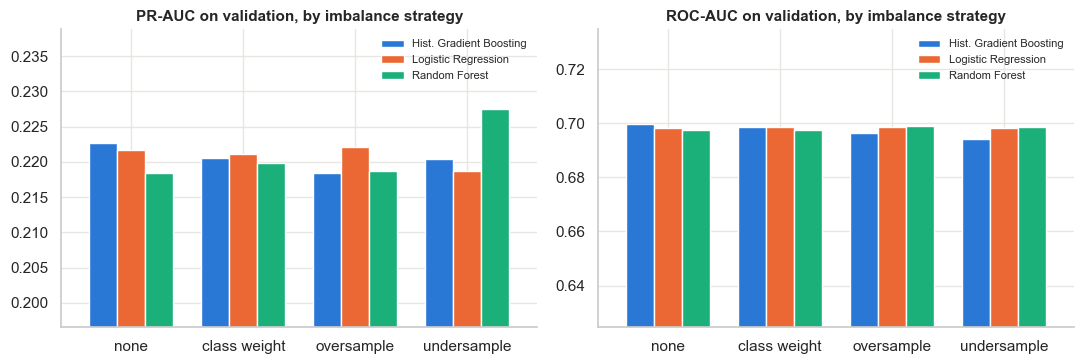

,model,strategy,ROC-AUC,PR-AUC,recall@top20%,precision@top20%
0,Logistic Regression,none,0.698,0.222,0.446,0.238
1,Logistic Regression,class weight,0.699,0.221,0.444,0.237
2,Logistic Regression,oversample,0.699,0.222,0.440,0.235
3,Logistic Regression,undersample,0.698,0.219,0.439,0.234
4,Hist. Gradient Boosting,none,0.700,0.223,0.448,0.239
5,Hist. Gradient Boosting,class weight,0.698,0.221,0.446,0.238
6,Hist. Gradient Boosting,oversample,0.696,0.218,0.448,0.239
7,Hist. Gradient Boosting,undersample,0.694,0.220,0.444,0.237
8,Random Forest,none,0.698,0.218,0.446,0.238
9,Random Forest,class weight,0.698,0.220,0.445,0.237


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, metric in zip(ax, ["PR-AUC", "ROC-AUC"]):
    pv = imb.pivot(index="strategy", columns="model", values=metric).reindex(list(strategies))
    pv.plot(kind="bar", ax=a, width=0.75, color=[BLUE, ORANGE, "#1baf7a"], rot=0)
    a.set_title(metric + " on validation, by imbalance strategy"); a.set_xlabel(""); a.legend(frameon=False, fontsize=8)
    a.set_ylim(pv.values.min() * 0.9, pv.values.max() * 1.05)
plt.tight_layout(); plt.show()
imb.round(3)

The ranking quality (PR-AUC and ROC-AUC) is nearly the same whichever strategy I use, differences are in the third decimal and there is no consistent
pattern (undersampling gives the best random forest but a slightly worse gradient boosting), which I read as noise: the validation set only has about 800
fraud cases. This makes sense: with a 10% fraud rate there are already lots of fraud examples, so the model is not starved of them. Resampling / class weights
mostly change the *predicted probabilities* (they inflate them), which matters for setting the threshold but not for the ranking.

My choice: **train normally, with no resampling and no class weights.** I prefer this because the predicted probabilities then stay close
to the real fraud probability, which I need for the cost-based threshold and for explaining the score to the business. (I still check
the calibration in section 8.) Since the ranking is the same, nothing is lost.

### 7.3 Comparing models with time-series cross-validation

One validation split can be lucky. So on the training data I also run a **time-series cross-validation** (5 folds, each fold
tests on a later chunk than it trains on) and look at the average and spread of PR-AUC.

In [33]:
tscv = TimeSeriesSplit(n_splits=5)
cv_rows, fitted = [], {}
for mname, (model, scale) in make_models(None).items():
    pipe = build_pipe(model, ENG_NUM, ENG_CAT, scale)
    cv = cross_validate(pipe, X_tr, y_train, cv=tscv, scoring=["roc_auc", "average_precision"], n_jobs=1)
    pipe.fit(X_tr, y_train); fitted[mname] = pipe
    s = score_all(y_valid, pipe.predict_proba(X_va)[:, 1])
    cv_rows.append({"model": mname,
                    "CV PR-AUC (mean)": cv["test_average_precision"].mean(), "CV PR-AUC (std)": cv["test_average_precision"].std(),
                    "CV ROC-AUC (mean)": cv["test_roc_auc"].mean(), **{"valid " + k: v for k, v in s.items()}})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(3)

,CV PR-AUC (mean),CV PR-AUC (std),CV ROC-AUC (mean),valid ROC-AUC,valid PR-AUC,valid recall@top20%,valid precision@top20%
model,,,,,,,
Logistic Regression,0.219,0.019,0.706,0.698,0.222,0.446,0.238
Decision Tree,0.193,0.016,0.690,0.696,0.207,0.450,0.240
Random Forest,0.221,0.018,0.710,0.698,0.218,0.446,0.238
Hist. Gradient Boosting,0.215,0.018,0.707,0.700,0.223,0.448,0.239


Logistic regression, random forest and gradient boosting land in a narrow band: PR-AUC around 0.22 on validation versus a base rate of about 0.107, so roughly
2x better than random flagging. The single decision tree is a bit lower (CV PR-AUC 0.19). The spread between CV folds (std about 0.02) is larger than
the differences between the top three models, so I cannot really say one is better than another.
This is the first hint that the data itself limits the performance, not the choice of algorithm. Logistic regression does as well as
gradient boosting, which suggests that the relationships are mostly simple and additive (no complex interactions to find).

Let me tune the main candidates a bit anyway, to be fair to the more flexible models.

### 7.4 Hyperparameter tuning

Randomised search with the same time-series CV, scoring on PR-AUC (`average_precision`). Only the training data is used.

In [34]:
tuned = {}

# logistic regression: only C really matters
lr_model, _ = make_models(None)["Logistic Regression"]
gs = GridSearchCV(build_pipe(lr_model, ENG_NUM, ENG_CAT, True), {"model__C": [0.001, 0.01, 0.1, 1, 10]},
                  cv=tscv, scoring="average_precision", n_jobs=1).fit(X_tr, y_train)
tuned["Logistic Regression"] = gs
print("LR best:", gs.best_params_, "| CV PR-AUC:", round(gs.best_score_, 4))

# gradient boosting
hgb_model, _ = make_models(None)["Hist. Gradient Boosting"]
hgb_space = {"model__max_depth": [2, 3, 4, 6], "model__learning_rate": [0.02, 0.05, 0.1],
             "model__max_iter": [100, 200, 300], "model__min_samples_leaf": [20, 50, 100, 200],
             "model__l2_regularization": [0, 1, 5, 10]}
rs = RandomizedSearchCV(build_pipe(hgb_model, ENG_NUM, ENG_CAT, False), hgb_space, n_iter=15, cv=tscv,
                        scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_tr, y_train)
tuned["Hist. Gradient Boosting"] = rs
print("HGB best:", rs.best_params_, "| CV PR-AUC:", round(rs.best_score_, 4))

# random forest
rf_model, _ = make_models(None)["Random Forest"]
rf_space = {"model__n_estimators": [200, 300], "model__max_depth": [4, 6, 8, 12], "model__min_samples_leaf": [10, 30, 60, 100],
            "model__max_features": ["sqrt", 0.3, 0.5]}
rs2 = RandomizedSearchCV(build_pipe(rf_model, ENG_NUM, ENG_CAT, False), rf_space, n_iter=10, cv=tscv,
                         scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_tr, y_train)
tuned["Random Forest"] = rs2
print("RF best:", rs2.best_params_, "| CV PR-AUC:", round(rs2.best_score_, 4))

LR best: {'model__C': 0.001} | CV PR-AUC: 0.2263
HGB best: {'model__min_samples_leaf': 100, 'model__max_iter': 300, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__l2_regularization': 5} | CV PR-AUC: 0.2184
RF best: {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 4} | CV PR-AUC: 0.2231


In [35]:
tune_rows = []
for name, search in tuned.items():
    s = score_all(y_valid, search.best_estimator_.predict_proba(X_va)[:, 1])
    tune_rows.append({"model": name, "CV PR-AUC": search.best_score_, **{"valid " + k: v for k, v in s.items()}})
tune_table = pd.DataFrame(tune_rows).set_index("model")
tune_table.round(3)

,CV PR-AUC,valid ROC-AUC,valid PR-AUC,valid recall@top20%,valid precision@top20%
model,,,,,
Logistic Regression,0.226,0.698,0.221,0.445,0.237
Hist. Gradient Boosting,0.218,0.697,0.223,0.444,0.237
Random Forest,0.223,0.698,0.220,0.441,0.235


Tuning barely moves the numbers. All three tuned models are within about 0.01 PR-AUC of each other on validation.

### 7.5 Which feature groups actually help? (ablation)

I add the engineered feature groups one at a time on top of the original columns and check the validation score. I do it with both
logistic regression and gradient boosting. If a group doesn't improve the score, it just adds complexity.

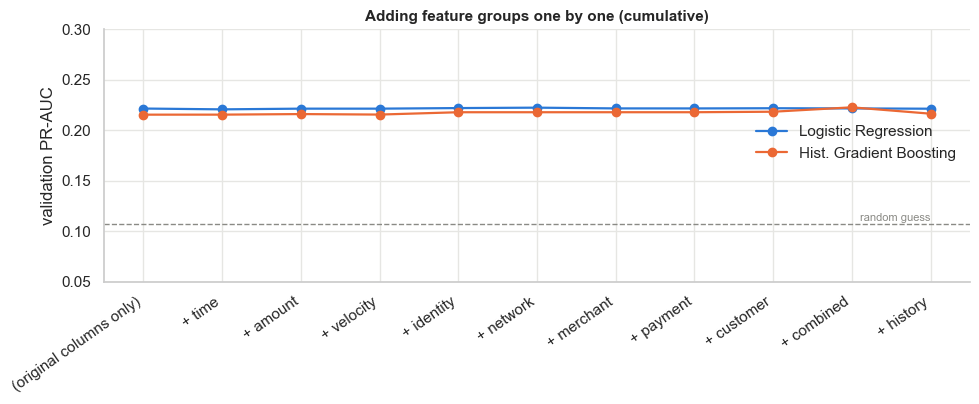

,Logistic Regression,Hist. Gradient Boosting
added group,,
(original columns only),0.2215,0.2154
+ time,0.2207,0.2155
+ amount,0.2214,0.2160
+ velocity,0.2214,0.2155
+ identity,0.2220,0.2178
+ network,0.2224,0.2178
+ merchant,0.2216,0.2178
+ payment,0.2216,0.2178
+ customer,0.2218,0.2183


In [36]:
def quick_eval(groups, mname):
    num, cat = features_for(groups)
    model, scale = make_models(None)[mname]
    pipe = build_pipe(model, num, cat, scale).fit(X_tr, y_train)
    return average_precision_score(y_valid, pipe.predict_proba(X_va)[:, 1])

abl = [{"added group": "(original columns only)", **{m: quick_eval([], m) for m in ["Logistic Regression", "Hist. Gradient Boosting"]}}]
so_far = []
for gname in ALL_GROUPS + ["history"]:
    so_far.append(gname)
    abl.append({"added group": "+ " + gname, **{m: quick_eval(so_far, m) for m in ["Logistic Regression", "Hist. Gradient Boosting"]}})
abl = pd.DataFrame(abl).set_index("added group")

ax = abl.plot(marker="o", figsize=(10, 4.2), color=[BLUE, ORANGE], lw=1.6)
ax.set_xticks(range(len(abl))); ax.set_xticklabels(abl.index, rotation=35, ha="right")     # show every label
ax.set_ylim(0.05, 0.30)     # wide enough to show that the differences are tiny; a zoomed axis would make noise look like a trend
ax.axhline(y_valid.mean(), color=GREY, ls="--", lw=1); ax.text(len(abl) - 1, y_valid.mean() + 0.003, "random guess", ha="right", fontsize=8, color=GREY)
ax.set_ylabel("validation PR-AUC"); ax.set_xlabel(""); ax.set_title("Adding feature groups one by one (cumulative)"); ax.legend(frameon=False, loc="center right", bbox_to_anchor=(1.0, 0.55))
plt.tight_layout(); plt.show()
abl.round(4)

The lines are basically flat. Adding any group moves the validation PR-AUC by less than 0.01 in either direction, which is smaller than the fold-to-fold
spread I saw in the cross-validation (std about 0.02), so none of the additions is a real improvement. The original columns already contain everything
the models can use, and the engineered features that score well on their own (`identity_change_count`, `combined_risk_index`, `high_ip_risk`) are only
re-expressions of the same three signals. The history, amount, velocity and time features add nothing.

So my decision for the final feature set is a **lean set** with only the four original columns that have evidence behind them:
`ip_address_risk_score`, `device_change_flag`, `location_change_flag` and `is_international`. I leave out all the engineered features, including the
ones that look good on their own (`identity_change_count`, `combined_risk_index`, `high_ip_risk`, `both_changed`), because they add no accuracy and they make a
logistic regression harder to interpret (several columns carrying the same information). A smaller model is also easier to run in real time, easier to explain to the risk team
and less likely to fit noise. So the feature engineering work was useful as a *test* of the usual fraud heuristics, but the final model does not need it.

One caveat about my own process: I picked these columns after looking at EDA and tests on the full dataset (which includes the test months).
The train-only table in 5.2 points to the same columns and the effects are big enough that I do not think the choice is fragile, but a stricter process
would do all the screening on the training data only.

In [37]:
LEAN_NUM = ["ip_address_risk_score", "device_change_flag", "location_change_flag", "is_international"]
LEAN_CAT = []

compare = {}
for label, (num, cat) in {"lean set": (LEAN_NUM, LEAN_CAT), "all engineered": (ENG_NUM, ENG_CAT), "original only": (BASE_NUM, BASE_CAT)}.items():
    for mname in ["Logistic Regression", "Hist. Gradient Boosting"]:
        model, scale = make_models(None)[mname]
        p = build_pipe(model, num, cat, scale).fit(X_tr, y_train).predict_proba(X_va)[:, 1]
        compare[(label, mname)] = score_all(y_valid, p)
pd.DataFrame(compare).T.round(3)

ROC-AUC  PR-AUC  recall@top20%  precision@top20%
lean set       Logistic Regression        0.698   0.221          0.441             0.235
               Hist. Gradient Boosting    0.694   0.212          0.442             0.236
all engineered Logistic Regression        0.698   0.222          0.446             0.238
               Hist. Gradient Boosting    0.700   0.223          0.448             0.239
original only  Logistic Regression        0.700   0.221          0.445             0.237
               Hist. Gradient Boosting    0.699   0.215          0.448             0.239

For logistic regression the lean set (4 columns) is as good as the set with all engineered features (43 columns) and the original columns (19). Gradient boosting scores a
little lower on it (0.212 vs 0.215 to 0.223), which is within the noise I saw in the cross-validation. So I go with the lean set.

### 7.6 Final model choice

I re-tune the two best candidate types on the lean feature set (logistic regression and gradient boosting), and choose using a
simple rule: **pick the simplest model that is within 0.005 PR-AUC of the best one on validation**. (For logistic regression the CV score is almost flat in the
regularisation strength C, so there I also use a rule instead of crowning a tiny winner, see the comment in the code.) Logistic regression is the simplest,
then gradient boosting. Reason: when performance is tied I would rather have the model which is easier to explain, audit (regulators
like that) and run at low latency.

In [38]:
lr_model, _ = make_models(None)["Logistic Regression"]
lr_search = GridSearchCV(build_pipe(lr_model, LEAN_NUM, LEAN_CAT, True), {"model__C": [0.0001, 0.001, 0.01, 0.1, 1, 10]},
                         cv=tscv, scoring="average_precision", n_jobs=1).fit(X_tr, y_train)
lr_cv = pd.DataFrame(lr_search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
print(lr_cv.round(4).to_string(index=False))

# The CV score is basically flat in C (differences in the 3rd decimal), so I do not want to crown the tiny "winner", especially as it sits at the edge of my grid.
# Rule: take the LEAST regularised C that is within 0.001 of the best score. That gives coefficients close to a plain logistic regression.
best_s = lr_cv.mean_test_score.max()
C_final = float(lr_cv.loc[lr_cv.mean_test_score >= best_s - 0.001, "param_model__C"].astype(float).max())
lr_final = build_pipe(LogisticRegression(C=C_final, max_iter=3000), LEAN_NUM, LEAN_CAT, True).fit(X_tr, y_train)
print("chosen C for logistic regression:", C_final)

hgb_model, _ = make_models(None)["Hist. Gradient Boosting"]
hgb_search = RandomizedSearchCV(build_pipe(hgb_model, LEAN_NUM, LEAN_CAT, False), hgb_space, n_iter=15,
                                cv=tscv, scoring="average_precision", random_state=SEED, n_jobs=1).fit(X_tr, y_train)

final_models = {"Logistic Regression": lr_final, "Hist. Gradient Boosting": hgb_search.best_estimator_}
cv_pr = {"Logistic Regression": float(lr_cv.loc[lr_cv.param_model__C.astype(float) == C_final, "mean_test_score"].iloc[0]),
         "Hist. Gradient Boosting": hgb_search.best_score_}
rows = []
for name, m in final_models.items():
    rows.append({"model": name, "CV PR-AUC": cv_pr[name], **score_all(y_valid, m.predict_proba(X_va)[:, 1])})
final_cmp = pd.DataFrame(rows).set_index("model")

best_pr = final_cmp["PR-AUC"].max()
order = ["Logistic Regression", "Hist. Gradient Boosting"]                    # simplest first
final_name = next(m for m in order if final_cmp.loc[m, "PR-AUC"] >= best_pr - 0.005)
print("Chosen final model:", final_name)
final_cmp.round(4)

 param_model__C  mean_test_score  std_test_score
         0.0001           0.2271          0.0182
         0.0010           0.2269          0.0186
         0.0100           0.2266          0.0186
         0.1000           0.2263          0.0187
         1.0000           0.2263          0.0187
        10.0000           0.2263          0.0187
chosen C for logistic regression: 10.0
Chosen final model: Logistic Regression


,CV PR-AUC,ROC-AUC,PR-AUC,recall@top20%,precision@top20%
model,,,,,
Logistic Regression,0.2263,0.6977,0.2213,0.4412,0.2353
Hist. Gradient Boosting,0.2203,0.6952,0.2118,0.4438,0.2367


In [39]:
final_pipe = final_models[final_name]
print(final_pipe.named_steps["model"])

LogisticRegression(C=10.0, max_iter=3000)


## 8. Final model evaluation on the test set

This is the first time the test data is used. The model was fitted on the training data only. To turn the raw model output into a proper
probability I add a small **Platt calibration** step (a 1-feature logistic regression on the model's log-odds), fitted on the
validation set. This does not change the ranking (so ROC-AUC/PR-AUC stay the same), it only makes the numbers behave like real probabilities.

In [40]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

p_val_raw = final_pipe.predict_proba(X_va)[:, 1]
p_test_raw = final_pipe.predict_proba(test)[:, 1]
calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_val_raw), y_valid)
p_val = calibrator.predict_proba(logit(p_val_raw))[:, 1]
p_test = calibrator.predict_proba(logit(p_test_raw))[:, 1]

print("Test ROC-AUC:", round(roc_auc_score(y_test, p_test), 4), "| PR-AUC:", round(average_precision_score(y_test, p_test), 4),
      "| test base rate:", round(y_test.mean(), 4))
print("Brier score before / after calibration:", round(brier_score_loss(y_test, p_test_raw), 4), "/", round(brier_score_loss(y_test, p_test), 4))

Test ROC-AUC: 0.7176 | PR-AUC: 0.231 | test base rate: 0.1008
Brier score before / after calibration: 0.0849 / 0.0848


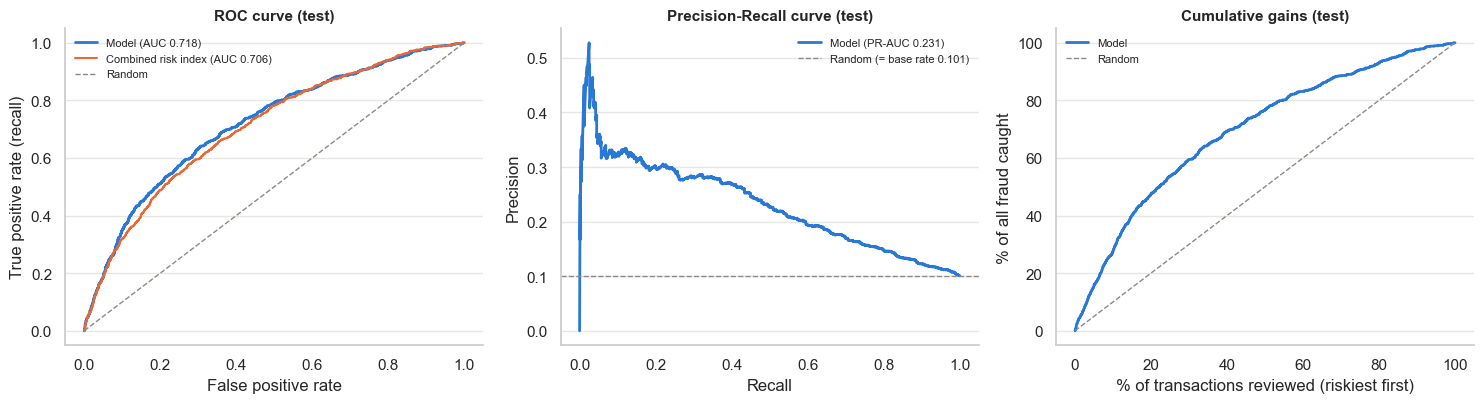

Top 5% riskiest -> catches 15.6% of fraud (lift 3.12x), precision 31.5%
Top 10% riskiest -> catches 27.5% of fraud (lift 2.75x), precision 27.7%
Top 20% riskiest -> catches 47.5% of fraud (lift 2.37x), precision 23.9%
Top 30% riskiest -> catches 59.5% of fraud (lift 1.98x), precision 20.0%


In [41]:
# ROC and PR curves on the test set, with the baselines
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

fpr, tpr, _ = roc_curve(y_test, p_test)
ax[0].plot(fpr, tpr, color=BLUE, lw=2, label=f"Model (AUC {roc_auc_score(y_test, p_test):.3f})")
f2, t2, _ = roc_curve(y_test, test.combined_risk_index)
ax[0].plot(f2, t2, color=ORANGE, lw=1.5, label=f"Combined risk index (AUC {roc_auc_score(y_test, test.combined_risk_index):.3f})")
ax[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Random")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curve (test)"); ax[0].legend(frameon=False, fontsize=8)

pr, rc, _ = precision_recall_curve(y_test, p_test)
ax[1].plot(rc[:-1], pr[:-1], color=BLUE, lw=2, label=f"Model (PR-AUC {average_precision_score(y_test, p_test):.3f})")
ax[1].axhline(y_test.mean(), color=GREY, ls="--", lw=1, label=f"Random (= base rate {y_test.mean():.3f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-Recall curve (test)"); ax[1].legend(frameon=False, fontsize=8)

# cumulative gains: what share of fraud do we catch if we look at the top X% riskiest transactions
order_ = np.argsort(-p_test)
gain = np.cumsum(y_test.values[order_]) / y_test.sum()
x = np.arange(1, len(y_test) + 1) / len(y_test)
ax[2].plot(x * 100, gain * 100, color=BLUE, lw=2, label="Model")
ax[2].plot([0, 100], [0, 100], color=GREY, ls="--", lw=1, label="Random")
ax[2].set_xlabel("% of transactions reviewed (riskiest first)"); ax[2].set_ylabel("% of all fraud caught"); ax[2].set_title("Cumulative gains (test)")
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

for frac in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(y_test) * frac)
    caught = y_test.values[order_[:k]].sum() / y_test.sum()
    print(f"Top {frac:.0%} riskiest -> catches {caught:.1%} of fraud (lift {caught/frac:.2f}x), precision {y_test.values[order_[:k]].mean():.1%}")

In [42]:
# Honest check: does the model actually beat the simple rule "device OR location changed"?
rule_t = ((test.device_change_flag == 1) | (test.location_change_flag == 1)).values
yy = y_test.values
k_rule = int(rule_t.sum()); top_k = np.argsort(-p_test)[:k_rule]
print(f"Simple rule flags {rule_t.mean():.1%} of the test transactions: precision {yy[rule_t].mean():.1%}, recall {yy[rule_t].sum() / yy.sum():.1%}")
print(f"Model flagging the same number ({k_rule}):          precision {yy[top_k].mean():.1%}, recall {yy[top_k].sum() / yy.sum():.1%}")

Simple rule flags 17.3% of the test transactions: precision 25.7%, recall 44.2%
Model flagging the same number (1299):          precision 25.3%, recall 43.5%


So at this operating point (about 17% of transactions flagged) the model is **not better** than the simple two-flag rule: they flag the same share and catch about the same
fraud. That is a slightly disappointing result, but it fits everything else I have seen: the signal sits in those two flags, and IP risk adds only a little. What the model adds is:
(1) a graded score, so the business can choose *how many* transactions to flag (the rule is stuck at one fixed group of about 17%), (2) a way to reach a higher recall by using
the IP risk score when the business is willing to challenge more transactions (about 75% recall at the cost-optimal threshold below, vs about 44% for the rule), and (3) risk tiers
for different actions. If PaySphere wanted the simplest thing that works on this data, the two-flag rule is a reasonable start and the model is an upgrade path.

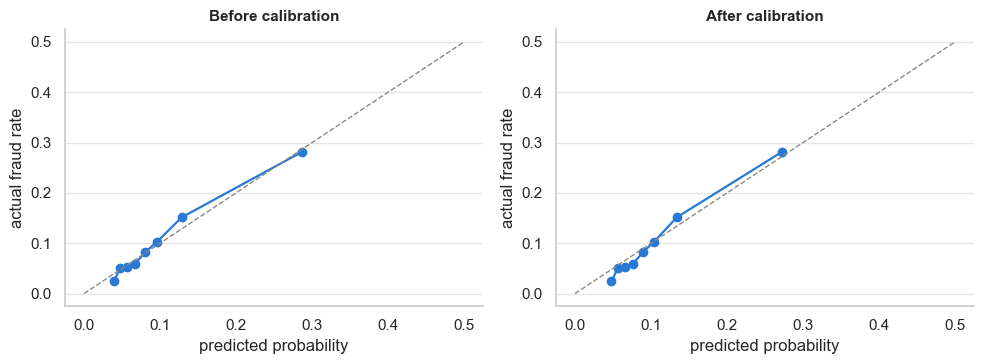

In [43]:
# calibration check
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, p, title in [(ax[0], p_test_raw, "Before calibration"), (ax[1], p_test, "After calibration")]:
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=8, strategy="quantile")
    a.plot(mean_pred, frac_pos, marker="o", color=BLUE, lw=1.6)
    a.plot([0, 0.5], [0, 0.5], color=GREY, ls="--", lw=1)
    a.set_xlabel("predicted probability"); a.set_ylabel("actual fraud rate"); a.set_title(title)
plt.tight_layout(); plt.show()

**Reading the results honestly.** The model is clearly better than random: test ROC-AUC is about 0.72 (random = 0.5) and PR-AUC about 0.23 against a base
rate of 0.10, so 2.3 times better. If the fraud team could only review the riskiest 20% of transactions, they would catch about 47% of all fraud
(a lift of 2.4). It is a *moderate* model, not a great one, and it cannot get much better with these columns, because as seen in the EDA more than
half of the fraud has no device change, no location change and an average IP risk, so it looks like a normal transaction.
The calibration plots look almost the same before and after (Brier score 0.0849 vs 0.0848), because logistic regression trained without class weights already gives
well calibrated probabilities. I keep the step anyway, since it protects the risk score if the model is later swapped for a class-weighted or tree-based one.

## 9. Threshold tuning

A model gives a probability. Someone has to decide above which probability we act. Using the default 0.5 would be silly here: the
maximum calibrated probability in the data is only about 0.63, so at 0.5 we would catch almost nothing. So I tune the threshold on
the **validation set** using a cost view.

**Cost assumptions (mine, and easy to change):**

* **Missed fraud (false negative)** costs the transaction amount (the money is lost through the chargeback) plus a chargeback handling fee of **Rs. 300**.
* **False alarm (false positive)**: the cost depends on how heavy the action is. For the lightest action (an OTP / step-up challenge) I assume an
  effective cost of **Rs. 1,000** per genuine customer affected. That is not the SMS cost, it is meant to include customers who drop the payment,
  extra support calls, and the fact that an OTP does not stop every fraud. Heavier actions cost more, I use higher numbers for them in section 10.
* Doing nothing (no model) costs all the fraud losses.

Because these are assumptions, I also show how the best threshold moves if the false-alarm cost is different.

In [44]:
CB_FEE = 300
FP_COST = 1000            # effective cost of a false alarm for the lightest action (OTP / step-up)

def cost_at(y, p, amount, thr, fp_cost=FP_COST):
    flag = p >= thr
    fn_cost = ((amount + CB_FEE) * ((y == 1) & ~flag)).sum()
    fp_total = fp_cost * ((y == 0) & flag).sum()
    return fn_cost + fp_total

yv, av = y_valid.values, valid.amount.values
no_model_cost = ((av + CB_FEE) * (yv == 1)).sum()
thr_grid = np.round(np.arange(0.02, 0.60, 0.005), 3)

def best_threshold(fp_cost):
    """threshold with the lowest total cost on the validation set, for a given false alarm cost"""
    costs = [cost_at(yv, p_val, av, t, fp_cost) for t in thr_grid]
    return float(thr_grid[int(np.argmin(costs))])

rows = []
for t in thr_grid:
    flag = p_val >= t
    tp_ = ((yv == 1) & flag).sum()
    prec = tp_ / max(flag.sum(), 1); rec = tp_ / yv.sum()
    rows.append({"threshold": t, "flag_rate": flag.mean(), "precision": prec, "recall": rec,
                 "F1": 2 * prec * rec / max(prec + rec, 1e-9), "total_cost": cost_at(yv, p_val, av, t)})
tt = pd.DataFrame(rows)
tt["saving_vs_no_model"] = no_model_cost - tt.total_cost

best_cost_row = tt.loc[tt.total_cost.idxmin()]
best_f1_row = tt.loc[tt.F1.idxmax()]
print("Cost-optimal threshold: {:.3f} -> flags {:.1%}, precision {:.1%}, recall {:.1%}".format(
    best_cost_row.threshold, best_cost_row.flag_rate, best_cost_row.precision, best_cost_row.recall))
print("F1-optimal threshold  : {:.3f} -> flags {:.1%}, precision {:.1%}, recall {:.1%}".format(
    best_f1_row.threshold, best_f1_row.flag_rate, best_f1_row.precision, best_f1_row.recall))
print("Highest calibrated probability on validation: {:.3f}".format(p_val.max()))

Cost-optimal threshold: 0.085 -> flags 48.5%, precision 16.0%, recall 73.0%
F1-optimal threshold  : 0.125 -> flags 18.4%, precision 24.8%, recall 42.9%
Highest calibrated probability on validation: 0.633


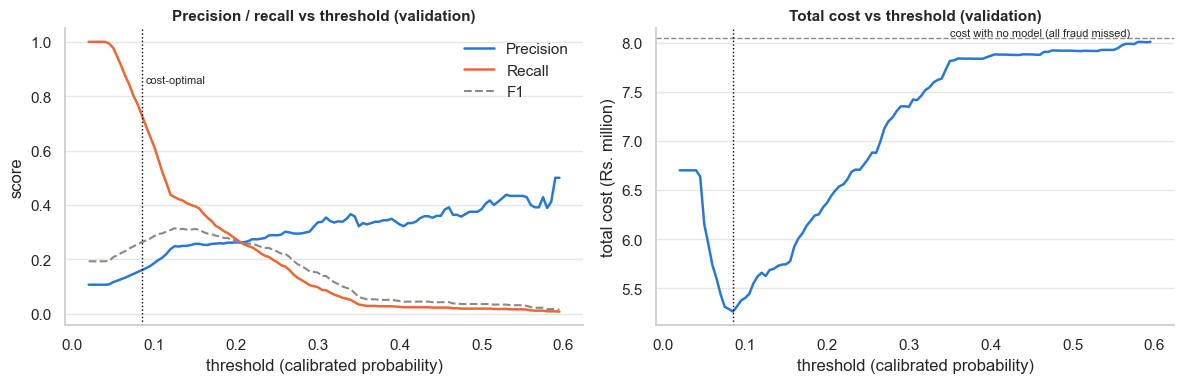

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tt.threshold, tt.precision, color=BLUE, lw=1.8, label="Precision")
ax[0].plot(tt.threshold, tt.recall, color=ORANGE, lw=1.8, label="Recall")
ax[0].plot(tt.threshold, tt.F1, color=GREY, lw=1.5, ls="--", label="F1")
ax[0].axvline(best_cost_row.threshold, color="black", lw=1, ls=":")
ax[0].text(best_cost_row.threshold + 0.005, 0.85, "cost-optimal", fontsize=8)
ax[0].set_xlabel("threshold (calibrated probability)"); ax[0].set_ylabel("score"); ax[0].set_title("Precision / recall vs threshold (validation)")
ax[0].legend(frameon=False)

ax[1].plot(tt.threshold, tt.total_cost / 1e6, color=BLUE, lw=1.8)
ax[1].axhline(no_model_cost / 1e6, color=GREY, ls="--", lw=1)
ax[1].text(0.35, no_model_cost / 1e6, "cost with no model (all fraud missed)", va="bottom", fontsize=8)
ax[1].axvline(best_cost_row.threshold, color="black", lw=1, ls=":")
ax[1].set_xlabel("threshold (calibrated probability)"); ax[1].set_ylabel("total cost (Rs. million)"); ax[1].set_title("Total cost vs threshold (validation)")
plt.tight_layout(); plt.show()

In [46]:
# sensitivity to the false-alarm cost assumption
sens = []
for fp in [250, 500, 1000, 2000, 3000, 5000]:
    t = best_threshold(fp); flag = p_val >= t
    sens.append({"false alarm cost (Rs.)": fp, "best threshold": t, "flag rate": f"{flag.mean():.1%}",
                 "precision": f"{((yv==1)&flag).sum()/max(flag.sum(),1):.1%}", "recall": f"{((yv==1)&flag).sum()/yv.sum():.1%}",
                 "saving vs no model (Rs. lakh)": round((no_model_cost - cost_at(yv, p_val, av, t, fp)) / 1e5, 1)})
pd.DataFrame(sens)

,false alarm cost (Rs.),best threshold,flag rate,precision,recall,saving vs no model (Rs. lakh)
0,250,0.020,100.0%,10.7%,100.0%,63.7
1,500,0.050,89.7%,11.6%,97.8%,48.7
2,1000,0.085,48.5%,16.0%,73.0%,27.9
3,2000,0.150,16.4%,25.7%,39.5%,13.9
4,3000,0.260,6.1%,30.2%,17.4%,5.3
5,5000,0.340,1.5%,36.6%,5.1%,1.3


What this says:

* A missed fraud costs about 10 times more than a false alarm at Rs. 1,000, so the cost-optimal cut-off is low (about 0.085, close to the base rate of
  fraud). It flags around 48% of transactions and catches about 73% of the fraud cases on validation, but only about 16% of the flagged transactions are really fraud.
  The reason is that the fraud rate here is already 10%, which is above the break-even point for a large share of transactions, so a light step-up
  check on a big share of the traffic is what the maths says. On real PaySphere data with fraud below 0.5% this share would be far smaller, so the
  thresholds must be recomputed on real data.
* The F1-optimal threshold (about 0.125) is less aggressive (flags 18%, recall 43%), but F1 treats both errors as equally costly, which is not true here.
* The best cut-off moves a lot with the false-alarm cost (table above): at Rs. 250 the answer is to challenge everyone, at Rs. 5,000 only about 1.5% of
  transactions get flagged. That is why the next section uses several tiers with different friction levels and not one single cut-off.
* All savings shown are *modelled* savings under my cost assumptions, not measured savings.

Threshold 0.085 on TEST set: flags 47.8% of transactions
              precision    recall  f1-score   support

     genuine      0.951     0.552     0.699      6744
       fraud      0.158     0.749     0.261       756

    accuracy                          0.572      7500
   macro avg      0.555     0.650     0.480      7500
weighted avg      0.871     0.572     0.654      7500



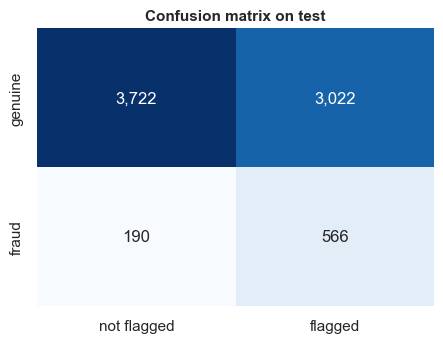

Fraud loss without a model (test period): Rs. 79.8 lakh
Fraud loss avoided: Rs. 60.7 lakh (76.0%)
Cost of false alarms: Rs. 30.2 lakh
Net saving: Rs. 30.4 lakh
For comparison: flagging the same 48% of transactions at random saves Rs. 5.9 lakh; challenging every transaction saves Rs. 12.4 lakh


In [47]:
THR_FLAG = float(best_cost_row.threshold)

# evaluate on the test set (threshold chosen on validation, no re-tuning)
yt, at_ = y_test.values, test.amount.values
flag_t = p_test >= THR_FLAG
tn, fp_, fn_, tp_ = confusion_matrix(yt, flag_t).ravel()
print(f"Threshold {THR_FLAG:.3f} on TEST set: flags {flag_t.mean():.1%} of transactions")
print(classification_report(yt, flag_t, target_names=["genuine", "fraud"], digits=3))

fig, ax = plt.subplots(figsize=(4.6, 3.6))
sns.heatmap(np.array([[tn, fp_], [fn_, tp_]]), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["not flagged", "flagged"], yticklabels=["genuine", "fraud"])
ax.set_title("Confusion matrix on test"); plt.tight_layout(); plt.show()

fraud_total = ((at_ + CB_FEE) * (yt == 1)).sum()
caught_val = ((at_ + CB_FEE) * ((yt == 1) & flag_t)).sum()
false_alarm_cost = FP_COST * ((yt == 0) & flag_t).sum()
print(f"Fraud loss without a model (test period): Rs. {fraud_total/1e5:,.1f} lakh")
print(f"Fraud loss avoided: Rs. {caught_val/1e5:,.1f} lakh ({caught_val/fraud_total:.1%})")
print(f"Cost of false alarms: Rs. {false_alarm_cost/1e5:,.1f} lakh")
print(f"Net saving: Rs. {(caught_val-false_alarm_cost)/1e5:,.1f} lakh")

# what would simple alternatives have saved under the same cost assumptions?
n_gen = (yt == 0).sum()
rand_saving = flag_t.mean() * fraud_total - FP_COST * flag_t.mean() * n_gen        # flag the same share of transactions at random
flag_all_saving = fraud_total - FP_COST * n_gen                                   # challenge everybody
print(f"For comparison: flagging the same {flag_t.mean():.0%} of transactions at random saves Rs. {rand_saving/1e5:,.1f} lakh; "
      f"challenging every transaction saves Rs. {flag_all_saving/1e5:,.1f} lakh")

## 10. Risk score and recommended actions

PaySphere asked for a business-ready score and not just a yes/no. I turn the calibrated probability into a **risk score from 0 to 100**
(probability x 100) and split it into four tiers, each with a different action, matching the actions a payments risk team would use.

I set the tier boundaries with the same cost logic as in section 9. The heavier the action, the more it costs when it hits a genuine customer,
so it should only be used when the fraud probability is higher:

| Action | assumed cost if it hits a genuine customer (Rs.) |
|---|---|
| OTP / step-up challenge | 1,000 |
| Hold for manual review | 3,000 (analyst time, delay, customer irritation) |
| Hard block | 5,000 (lost sale, support call, real risk of losing the customer) |

For each cost I take the threshold with the lowest total cost on the **validation** set (the test set is not used to set anything). These costs are
my assumptions, so they are easy to change, and the notebook recomputes the boundaries when they are changed.

In [48]:
ACTION_COST = {"otp": 1000, "review": 3000, "block": 5000}
T_OTP, T_REVIEW, T_BLOCK = (best_threshold(ACTION_COST[k]) for k in ["otp", "review", "block"])
print(f"Tier boundaries (calibrated probability): OTP >= {T_OTP}, manual review >= {T_REVIEW}, hard block >= {T_BLOCK}")

# fraud rate in each slice on the validation data, to see that the boundaries make sense
bins = [0, T_OTP, T_REVIEW, T_BLOCK, 1.0]
slice_tab = pd.DataFrame({"p": p_val, "y": yv})
slice_tab["band"] = pd.cut(slice_tab.p, bins, include_lowest=True, right=False)
slice_tab.groupby("band", observed=True).agg(transactions=("y", "size"), fraud_rate=("y", "mean")).assign(
    share_of_txns=lambda x: (x.transactions / len(slice_tab)).round(3)).round(3)

Tier boundaries (calibrated probability): OTP >= 0.085, manual review >= 0.26, hard block >= 0.34


,transactions,fraud_rate,share_of_txns
band,,,
"[0.0, 0.085)",3860,0.056,0.515
"[0.085, 0.26)",3179,0.140,0.424
"[0.26, 0.34)",349,0.281,0.047
"[0.34, 1.0)",112,0.366,0.015


In [49]:
def risk_score(p):
    return np.round(100 * np.asarray(p), 1)

def assign_action(p, device_changed):
    """returns tier, action and a device-lock flag for each transaction"""
    p = np.asarray(p); dc = np.asarray(device_changed)
    tier = np.select([p >= T_BLOCK, p >= T_REVIEW, p >= T_OTP], ["4 - High", "3 - Medium-high", "2 - Medium"], default="1 - Low")
    action = np.select([p >= T_BLOCK, p >= T_REVIEW, p >= T_OTP],
                       ["Hard block", "Hold for manual review", "OTP / step-up challenge"], default="Allow")
    device_lock = (p >= T_REVIEW) & (dc == 1)        # high risk AND it came from a new device -> also lock that device on the account
    return tier, action, device_lock

tier_t, action_t, lock_t = assign_action(p_test, test.device_change_flag)
res = pd.DataFrame({"tier": tier_t, "action": action_t, "fraud": yt, "amount": at_})
tier_summary = res.groupby("tier").agg(transactions=("fraud", "size"), fraud_cases=("fraud", "sum"), fraud_rate=("fraud", "mean"),
                                       amount_at_stake=("amount", "sum"))
tier_summary["share_of_txns"] = tier_summary.transactions / len(res)
tier_summary["share_of_all_fraud"] = tier_summary.fraud_cases / res.fraud.sum()
tier_summary["fraud_amount"] = res[res.fraud == 1].groupby("tier").amount.sum()
tier_summary["share_of_fraud_value"] = tier_summary.fraud_amount / res.loc[res.fraud == 1, "amount"].sum()
tier_summary = tier_summary.fillna(0)
tier_summary[["transactions", "share_of_txns", "fraud_cases", "fraud_rate", "share_of_all_fraud", "share_of_fraud_value"]].round(3)

,transactions,share_of_txns,fraud_cases,fraud_rate,share_of_all_fraud,share_of_fraud_value
tier,,,,,,
1 - Low,3912,0.522,190,0.049,0.251,0.240
2 - Medium,3159,0.421,436,0.138,0.577,0.587
3 - Medium-high,314,0.042,89,0.283,0.118,0.124
4 - High,115,0.015,41,0.357,0.054,0.049


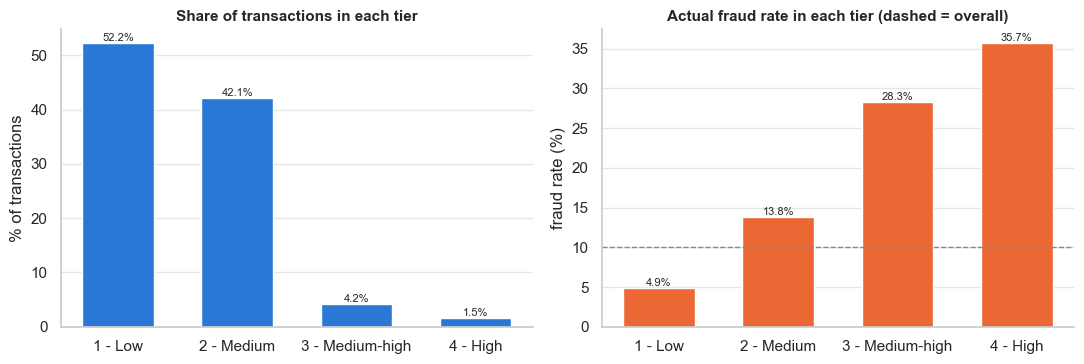

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ts_ = tier_summary.reset_index()
ax[0].bar(ts_.tier, ts_.share_of_txns * 100, color=BLUE, width=0.6)
ax[0].set_title("Share of transactions in each tier"); ax[0].set_ylabel("% of transactions")
for i, v in enumerate(ts_.share_of_txns * 100):
    ax[0].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
ax[1].bar(ts_.tier, ts_.fraud_rate * 100, color=ORANGE, width=0.6)
ax[1].axhline(y_test.mean() * 100, color=GREY, ls="--", lw=1)
ax[1].set_title("Actual fraud rate in each tier (dashed = overall)"); ax[1].set_ylabel("fraud rate (%)")
for i, v in enumerate(ts_.fraud_rate * 100):
    ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

The tiers separate risk properly on the test data: the fraud rate goes up from tier to tier (about 5% in tier 1, 14% in tier 2, 28% in tier 3 and 36% in tier 4).
The top two tiers hold under 6% of the transactions but their fraud rate is around three times the overall average, so it makes sense to spend expensive
analyst time only there. Tier 1 is more than half of the traffic with about half the average fraud rate, so it can stay frictionless. It is a real, usable
ordering, even though it is not a perfect detector: tier 1 still contains about a quarter of all fraud (the "quiet" fraud that has no visible warning sign).

In [51]:
# Demo: score a few example transactions from the test set with the final scoring function.
def score_transactions(raw_df, pipeline=final_pipe, cal=calibrator):
    """raw_df: transactions with the original 25-column layout (cleaned). Returns risk score, tier and action for each."""
    d = add_features(raw_df)
    p_raw = pipeline.predict_proba(d)[:, 1]
    p = cal.predict_proba(logit(p_raw))[:, 1]
    tier, action, lock = assign_action(p, d.device_change_flag)
    return pd.DataFrame({"transaction_id": d.transaction_id.values, "amount": d.amount.values, "fraud_probability": p.round(3),
                         "risk_score": risk_score(p), "tier": tier, "action": action, "device_lock": lock}, index=d.index)

demo = score_transactions(test.head(2000)).sort_values("risk_score", ascending=False)
demo.head(8)

,transaction_id,amount,fraud_probability,risk_score,tier,action,device_lock
42589,32186,12990.09,0.630,63.0,4 - High,Hard block,True
44343,17497,14980.09,0.626,62.6,4 - High,Hard block,True
44307,31643,3885.64,0.592,59.2,4 - High,Hard block,True
43311,43784,1953.04,0.591,59.1,4 - High,Hard block,True
42768,23188,17987.07,0.590,59.0,4 - High,Hard block,True
44048,24427,205.66,0.583,58.3,4 - High,Hard block,True
43368,3565,9054.79,0.575,57.5,4 - High,Hard block,True
44330,19850,10897.31,0.544,54.4,4 - High,Hard block,True


In [52]:
# save the scoring artifacts for the model
artifact = {"pipeline": final_pipe, "calibrator": calibrator, "num_features": LEAN_NUM, "cat_features": LEAN_CAT,
            "thresholds": {"otp": T_OTP, "review": T_REVIEW, "block": T_BLOCK}, "model_name": final_name,
            "cost_assumptions": {"chargeback_fee": CB_FEE, "false_alarm_cost_by_action": ACTION_COST}}
joblib.dump(artifact, "fraud_model.pkl")
print("saved fraud_model.pkl")

saved fraud_model.pkl


## 11. What drives the model, and where it fails

### 11.1 Feature importance

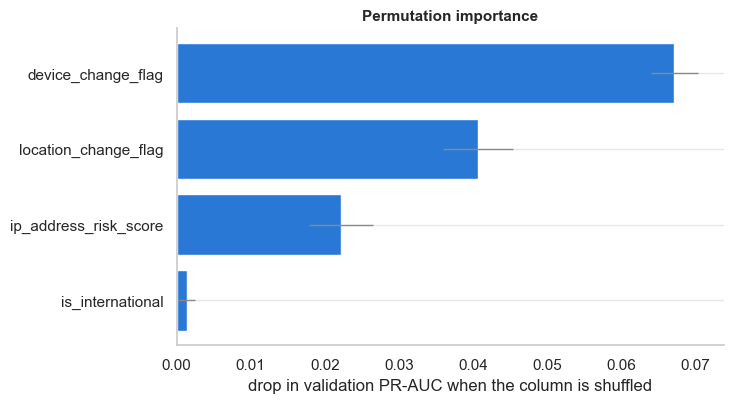

,feature,drop_in_PR-AUC,std
1,device_change_flag,0.0671,0.0032
2,location_change_flag,0.0407,0.0047
0,ip_address_risk_score,0.0221,0.0043
3,is_international,0.0013,0.0012


In [53]:
# permutation importance on the validation set: how much does PR-AUC drop when one column is shuffled?
pi = permutation_importance(final_pipe, X_va[LEAN_NUM + LEAN_CAT], y_valid, scoring="average_precision",
                            n_repeats=15, random_state=SEED, n_jobs=1)
pi_df = pd.DataFrame({"feature": LEAN_NUM + LEAN_CAT, "drop_in_PR-AUC": pi.importances_mean, "std": pi.importances_std}).sort_values(
    "drop_in_PR-AUC", ascending=True)
plt.figure(figsize=(7.5, 4.2))
plt.barh(pi_df.feature, pi_df["drop_in_PR-AUC"], xerr=pi_df["std"], color=BLUE, error_kw={"lw": 1, "ecolor": GREY})
plt.xlabel("drop in validation PR-AUC when the column is shuffled"); plt.title("Permutation importance")
plt.tight_layout(); plt.show()
pi_df.sort_values("drop_in_PR-AUC", ascending=False).round(4)

In [54]:
# if the final model is logistic regression, the coefficients can be turned into odds ratios, which the risk team can read easily
if final_name == "Logistic Regression":
    scaler = final_pipe.named_steps["prep"].named_transformers_["num"].named_steps["scale"]
    coef_raw = final_pipe.named_steps["model"].coef_[0] / scaler.scale_          # back to the original units of each column
    odds = pd.DataFrame({"coefficient": coef_raw, "odds ratio (per 1 unit)": np.exp(coef_raw)}, index=LEAN_NUM)
    print("Odds ratio = how much the odds of fraud are multiplied when the column goes up by 1 (for the 0-1 flags that is 'no' -> 'yes',")
    print("for ip_address_risk_score 1 unit is the whole 0-1 range):")
    display(odds.round(3))

Odds ratio = how much the odds of fraud are multiplied when the column goes up by 1 (for the 0-1 flags that is 'no' -> 'yes',
for ip_address_risk_score 1 unit is the whole 0-1 range):


,coefficient,odds ratio (per 1 unit)
ip_address_risk_score,1.256,3.510
device_change_flag,1.580,4.856
location_change_flag,1.314,3.720
is_international,0.362,1.436


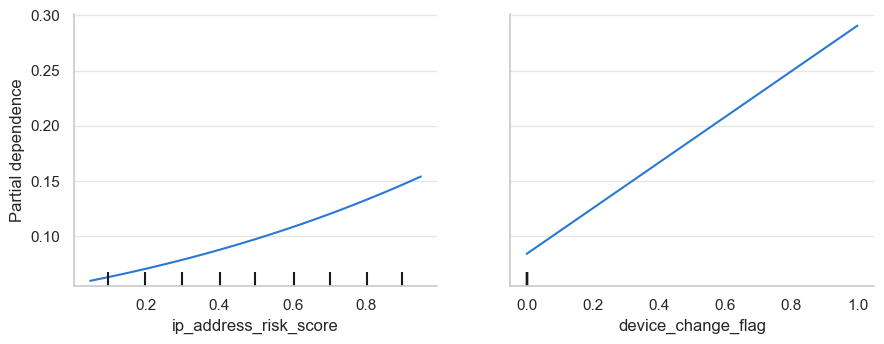

In [55]:
# partial dependence: what the predicted fraud probability does as IP risk goes up, and when the device changes
fig, ax = plt.subplots(figsize=(9, 3.6))
PartialDependenceDisplay.from_estimator(final_pipe, X_va[LEAN_NUM + LEAN_CAT], ["ip_address_risk_score", "device_change_flag"],
                                        ax=ax, line_kw={"color": BLUE})
plt.tight_layout(); plt.show()

The model relies on the two change flags and the IP risk score, exactly what the EDA and the tests showed. Reading the odds ratios: a device change multiplies the
odds of fraud by about 4.9, a location change by about 3.7, and moving from the lowest to the highest IP risk by about 3.5. `is_international` adds a small
extra (about 1.4). Permutation importance agrees: device change matters most, then location change, then IP risk. The predicted fraud probability
goes up smoothly as IP risk increases. Amount is not in the model, and the earlier tests showed it has no relationship with fraud.

### 11.2 Where does the model fail?

Now the errors at the chosen threshold on the test set. Which frauds do we miss, and which genuine transactions get flagged?

In [56]:
err = test[["transaction_id", "amount", "ip_address_risk_score", "device_change_flag", "location_change_flag", "is_international",
            "payment_method", "authentication_method", "is_fraud"]].copy()
err["flagged"] = flag_t
missed = err[(err.is_fraud == 1) & (~err.flagged)]
caught = err[(err.is_fraud == 1) & (err.flagged)]
false_al = err[(err.is_fraud == 0) & (err.flagged)]

prof = pd.DataFrame({
    "caught fraud": [len(caught), caught.device_change_flag.mean(), caught.location_change_flag.mean(), caught.ip_address_risk_score.mean(), caught.amount.mean()],
    "missed fraud": [len(missed), missed.device_change_flag.mean(), missed.location_change_flag.mean(), missed.ip_address_risk_score.mean(), missed.amount.mean()],
    "false alarms": [len(false_al), false_al.device_change_flag.mean(), false_al.location_change_flag.mean(), false_al.ip_address_risk_score.mean(), false_al.amount.mean()],
}, index=["count", "share with device change", "share with location change", "avg IP risk", "avg amount"]).T
prof.round(3)

,count,share with device change,share with location change,avg IP risk,avg amount
caught fraud,566.0,0.295,0.346,0.651,10417.629
missed fraud,190.0,0.000,0.000,0.374,9792.305
false alarms,3022.0,0.149,0.184,0.703,10005.635


In [57]:
# fraud that the model has no chance to see: no flags and low/average IP risk
quiet = test[(test.device_change_flag == 0) & (test.location_change_flag == 0)]
print(f"Fraud with no device change and no location change: {quiet.is_fraud.sum()} of {test.is_fraud.sum()} "
      f"({quiet.is_fraud.sum() / test.is_fraud.sum():.1%} of all fraud in test)")
print(f"Of the missed fraud, {((missed.device_change_flag == 0) & (missed.location_change_flag == 0)).mean():.1%} had neither flag.")

# check that one segment does not carry all the customer friction (fairness / customer experience)
seg = err.groupby("payment_method").agg(transactions=("flagged", "size"), flag_rate=("flagged", "mean"), fraud_rate=("is_fraud", "mean"))
seg["recall"] = err[err.is_fraud == 1].groupby("payment_method").flagged.mean()
seg.round(3)

Fraud with no device change and no location change: 422 of 756 (55.8% of all fraud in test)
Of the missed fraud, 100.0% had neither flag.


,transactions,flag_rate,fraud_rate,recall
payment_method,,,,
CARD,1838,0.472,0.096,0.774
NETBANKING,752,0.487,0.102,0.779
UPI,4171,0.485,0.106,0.739
WALLET,739,0.447,0.083,0.705


Every missed fraud is a "quiet" one (no device change, no location change) and has a lower IP risk than the fraud we catch (about 0.37 vs 0.65). Across the
whole test set, 422 of 756 fraud cases (56%) are quiet like this. The model still catches about half of them (232), but only because their IP risk is high,
and the price is false alarms: the flagged genuine transactions have an average IP risk of about 0.7, so they are mostly genuine customers who just happen to
have a high IP risk score. No other column separates them. On the friction side, the flag rate and recall are similar for UPI, cards, net banking and wallets
(flag rates 45% to 49%), so no payment channel carries a much bigger share of the friction.

## 12. Recommendations, limitations and next steps

### Summary of what I found

* **Data quality**: the file is clean in terms of nulls, duplicates, ranges and dates. The real problems are logical ones: 4,121 rows had an average
  amount with zero transactions (fixed), the ID columns behave randomly (merchants with 6 categories, customers with ~12 devices),
  `device_change_flag` disagrees with the device IDs, and the Data Definition does not match 10 of the 25 CSV columns.
* **Fraud rate is about 10%**, not <0.5% as documented. That is a moderate imbalance, and resampling or class weights made no difference to the ranking.
* **Only three signals really matter**: device change, location change and IP address risk score (plus a very small effect from international).
  A transaction with both a device and a location change is about 6 times more likely to be fraud than one with neither (42.8% vs 6.9%).
  Amount, time of day, day of week, payment method, merchant category, authentication method, device trust score and customer history showed **no
  significant relationship** with fraud.
* **Feature engineering**: I built more than 30 features from standard fraud heuristics (time, amount deviation, velocity, device / identity, merchant, payment, customer history,
  combined risk index, anomaly score). None of them improved validation PR-AUC beyond noise, so the final model uses only 4 original columns.
* **Model**: logistic regression on those 4 columns performs as well as the tuned gradient boosting and random forest. On the untouched test set the ROC-AUC is
  about 0.72 and the PR-AUC about 0.23 (base rate 0.10). Reviewing the riskiest 20% of transactions catches about 47% of the fraud.
  **But** at the same flag rate a simple rule ("device OR location changed") does about equally well (precision ~26%, recall ~44%). The model's added value is the graded score,
  the ability to trade recall for friction, and the use of IP risk to reach a higher recall.
* **Business result** (under my cost assumptions): at the cost-optimal threshold the model avoids about 76% of the fraud loss on the test period and has a modelled net
  saving of about Rs. 30 lakh, against about Rs. 6 lakh for flagging the same share of transactions at random and about Rs. 12 lakh for challenging everyone.
* **Risk tiers**: tier 1 (52% of transactions) is allowed with about 5% fraud; tier 2 (42%) gets an OTP / step-up at about 14% fraud; tier 3 (4%) goes to manual
  review at about 28% fraud; tier 4 (1.5%) is blocked at about 36% fraud.

### Recommendations for PaySphere

1. **Deploy the score as a 4-tier action framework** (allow / OTP step-up / manual review / hard block) and not as a single yes/no. Keep the frictionless path for tier 1,
   and reserve manual review and hard blocks for tiers 3 and 4 (under 6% of traffic), where the fraud rate is around three times the average.
2. **Build the core rules around new device, new location and IP reputation.** A transaction with both a device and a location change should never be auto-approved (43% fraud in
   this data). Also, IP risk is what creates most of the false alarms, so the Customer Experience team should check how the IP reputation feed is built (VPN users and shared networks).
3. **Add a device lock for tier 3 and 4 transactions that come from a new device.** Lock that device on the account until the customer verifies.
4. **Test whether the authentication step really helps before relying on it.** The fraud rate is the same for NONE, OTP, PIN and 3DS (about 9% to 10.5%), so this data cannot show
   that today's authentication reduces fraud, and tier 2 depends on OTP being an effective step-up. A small A/B test of step-up challenges would measure it properly.
5. **Do not build rules on amount, time of day, weekend or merchant category** unless real data shows an effect. In this data they are not riskier. Amount still matters for the cost
   of a miss, so it can be used to prioritise the manual review queue.
6. **Set the false-alarm costs together with the Customer Experience and Finance teams.** The thresholds depend strongly on them (section 9 sensitivity table). The business owns
   that decision, the model only shows the trade-off.
7. **Re-calibrate on real data and monitor.** Recompute the tier boundaries on data with the true fraud rate, monitor the fraud rate, score distribution and share of
   flagged genuine users weekly, and retrain regularly since fraud patterns change.

### Limitations

* The dataset looks simulated (uniform distributions, random IDs, almost no relationship between most columns and fraud), so these results should not be
  assumed to hold on real PaySphere data. Real data would probably give much stronger signals (device history, velocity, merchant risk).
* The ID columns are not consistent, so proper behavioural history features (customer profile, device familiarity, merchant history) could not be built. This is the
  biggest limit on model performance.
* The model is moderate: at the OTP threshold only about 16% of flagged transactions are fraud, so roughly 5 of 6 challenged customers are genuine. That friction is a real cost.
  More than half of the fraud has no warning sign in the data and can't be caught.
* The Data Definition and the CSV are not aligned; I used the CSV names and my own interpretation of a few columns.
* The cost numbers (Rs. 300 chargeback fee, Rs. 1,000 / 3,000 / 5,000 false-alarm costs by action) are my assumptions, and the tier boundaries follow from them. The savings are modelled, not measured.
* I chose the features after EDA and tests on the whole dataset, including the test months. The train-only check points to the same columns, but a stricter process would screen on training data only.
* Only 3 months of data, so seasonality (festival season, sale days) is not covered.
* The label is assumed final. In real life fraud labels arrive late (chargebacks take weeks), which affects training and monitoring.

### Next steps

* Try **SMOTE / other resampling** (needs `imbalanced-learn`) and **XGBoost / LightGBM**, although I do not expect a big gain given how flat the results were.
* Get real history features (proper customer and device IDs, 1h / 24h / 7d velocity, account tenure, country match) as the Data Definition describes.
* Set up **drift monitoring** and an analyst feedback loop for the manual review queue.
* Build an interactive dashboard on top of `score_transactions()` for the fraud analysts.

## Tools and acknowledgements

* Python libraries used: pandas, numpy, scipy, scikit-learn, matplotlib, seaborn, joblib.
* AI assistance: I used Claude (an AI assistant by Anthropic) to help me plan and write parts of this notebook. I ran the code and I am responsible for the analysis and conclusions.